# Forensic Auditing & Algorithmic Anti-Collusion Infrastructure
## Bulgarian National Recovery and Resilience Plan (NRRP / НПВУ) Procedure BG-RRP-1.015 "School STEM Environment"

**Deterministic Random Seed:** $\text{SEED} = 42$

---

## Introduction
Public procurement accounts for about 12% of GDP in OECD countries and is the government activity most exposed to waste and corruption (OECD, 2016). The procedure BG-RRP-1.015 "School STEM Environment" of the Bulgarian National Recovery and Resilience Plan is a case in which many small buyers, the schools, purchased similar equipment under rules that allow direct awards below legal value limits. The records of the Single Information Portal ISUN 2020 for this procedure contain 2,228 projects and 11,128 contracts (ISUN 2020, 2026). This notebook asks whether the contract values and the relations between buyers and suppliers in this programme show the patterns that the literature associates with manipulation of values and restricted competition, and how much of the programme's spending is affected. The indicators it produces are diagnostic signals, not findings of illegality.

## Theoretical Background

* **Discretionary Thresholds and the Manipulation of Contract Values.** Rules that let the buyer skip open competition below a value limit create an incentive to understate the estimated value of a contract. Where such a limit was introduced, estimated values accumulated just below it, and the accumulation was strongest among winners with concealed ownership (Palguta and Pertold, 2017). The same pattern, together with a fall in the density of contracts just above the limit, appears when discretion is granted below a limit in another country (Szűcs, 2024). Both studies therefore read a break in the density of contract values at a limit as evidence of manipulation, and compare the observed density with the one expected without the limit.
* **Discretion, Competition and Favouritism.** What happens after the value is brought under the limit is a separate question. In the Czech data the tenders concerned attracted fewer bids and ended at higher prices relative to the estimated value (Palguta and Pertold, 2017). In the Hungarian data discretion raised prices, selected less productive contractors and favoured firms connected to the governing party (Szűcs, 2024). Because buyers sort themselves below the limit, a simple comparison of contracts on either side of it is biased, and the effect is identified with a structural model of the buyer's choice of procedure (Szűcs, 2024).
* **Red Flags in the Procurement Cycle.** Beyond thresholds, integrity work lists the patterns that signal risk along the whole cycle: splitting a contract to stay below a threshold, tailor-made specifications, direct awards without justification, bid-rigging in its several forms and conflicts of interest of evaluators (OECD, 2016). Several of these leave a trace that can be screened for in data, including by combining procurement files with company and tax registers (OECD, 2016). Splitting is closely related to bunching: both respond to the same limit, one by lowering the estimated value and the other by dividing it.
* **Statistically Validated Networks and Control for Activity.** In a bipartite network of buyers and suppliers, two suppliers that serve many of the same buyers need not be related, because a supplier with many contracts shares buyers with others by chance alone. Tumminello et al. (2011) therefore test each pair of nodes against a hypergeometric null model and keep only the links that remain significant after correction for multiple testing with the false discovery rate. Saracco et al. (2017) replace the hypergeometric null model by the bipartite configuration model, which fixes the degrees of both sets of nodes and gives the exact distribution of the number of shared neighbours. Coscia and Neffke (2017) treat weighted links with a noise-corrected backbone that compares each link with the value expected from the strengths of its two end nodes. The disparity filter, which looks at one end node only, tends to keep the links of hubs.
* **Groups of Firms and Corruption Risk in Networks.** Wachs and Kertész (2019) detect groups of firms in the co-bidding network and describe each group by its coherence, the uniformity of the ties inside the group, and its exclusivity, the share of the ties of the group that stay inside it. Groups that score high on both are candidates for collusion. Wachs et al. (2021) map procurement markets as bipartite networks of issuers and winners and relate the share of single-bid contracts to the position of a node in the core or the periphery of the network and to its community, using null models that shuffle the contract flags within sectors.
* **Digit Patterns in Contract Values.** Miller and Nigrini (2006) show that the leading digits of the differences between ordered values drawn from a smooth density follow a distribution very close to Benford's law. Rounded or otherwise regular values break this pattern, which makes the digits of the spacings a screening tool for the values themselves.
* **Institutional Setting in Bulgaria.** In Bulgaria the limits below which a contracting authority may award a contract directly are set in the Public Procurement Act, and they were changed with effect from 1 January 2024 (Bulgaria, 2023, Art. 20(4)). A contract is therefore compared with different limits depending on its date.
* **Research Gap and Analytical Framework.** The evidence on thresholds comes from national procurement data of two countries and from one reform in each. It says little about a single programme in which many small buyers purchase similar equipment. This study applies the threshold test and red-flag screening to such a programme. It expects contract values to accumulate just below the legal limits and treats other red flags as additional risk indicators. The framework distinguishes four levels, which are a working structure of this study and not a finding. (1) *Funding and contracting authority:* funds of the Recovery and Resilience Plan reach schools, which award the contracts. (2) *Local and regional influence:* municipalities and the regional education directorates stand in institutional relations with schools. (3) *Supplier groups:* firms supplying construction, equipment and consultancy may appear together across the same buyers. (4) *Audit record:* the records of ISUN 2020 and the audit reports of the State Financial Inspection Agency (ADFI) allow the indicators to be compared with the outcome of inspections. The available data record the winning supplier only, so competition cannot be measured directly.

*Further sources are added to this section in the steps in which the corresponding methods are used.*

---

## 1. Scientific Stack Verification & Dependency Audit

The analysis requires the package versions listed in `requirements.txt`. Each package has the following role:

- **`numpy` ($\ge 2.5.4$) & `scipy` ($\ge 1.18.1$):** Array computation, hypergeometric tests for the validation of network links, and permutation null models.
- **`pandas` ($\ge 3.1.0$):** Tabular data processing, datetime indexing, multi-key aggregations, and high-throughput filtering.
- **`networkx` ($\ge 3.7$):** Construction of bipartite buyer-supplier networks $B = (S, V, E)$, their projection onto suppliers that share buyers, $k$-core decomposition and community detection.
- **`scikit-learn` ($\ge 1.9.1$) & `statsmodels` ($\ge 0.15.0$):** Polynomial counterfactual density estimation (bunching), Quasi-Maximum Likelihood (QML) Poisson regressions, and Regression Discontinuity Design (RDD).
- **`matplotlib` ($\ge 3.11.2$) & `seaborn` ($\ge 0.13.2$):** Figures at $300\text{ DPI}$.
- **`lxml` ($\ge 6.1.3$) & `xmlschema` ($\ge 4.3.2$):** Stream parsing and XML Schema Definition (XSD) validation of the $158\text{ MB}$ ISUN open-data file (`openData.xml`).
- **`torch` ($\ge 2.11.0$, CUDA 12.8 build):** GPU acceleration of Monte Carlo and stratified permutation tests on the buyer-supplier network.

**Environment installation.** Run from the notebook directory:

```
python -m pip install -r requirements.txt --extra-index-url https://download.pytorch.org/whl/cu128
```

The extra index provides the CUDA 12.8 build of `torch` required in `requirements.txt`.

In [1]:
import os
import sys
from pathlib import Path

# Windows: make the bundled MKL DLLs importable before the scientific stack loads
DLL_DIR = Path(sys.prefix) / "Library" / "bin"
if os.name == "nt" and DLL_DIR.is_dir():
    os.add_dll_directory(str(DLL_DIR))

import importlib.metadata as importlib_metadata

from packaging.version import Version

REQUIRED_VERSIONS: dict[str, str] = {
    "numpy": "2.5.4",
    "scipy": "1.18.1",
    "pandas": "3.1.0",
    "networkx": "3.7",
    "scikit-learn": "1.9.1",
    "matplotlib": "3.11.2",
    "seaborn": "0.13.2",
    "statsmodels": "0.15.0",
    "lxml": "6.1.3",
    "xmlschema": "4.3.2",
    "torch": "2.11.0",
    "jupyter": "1.1.1",
    "nbconvert": "7.17.2",
    "nbformat": "5.11.1",
}

below_minimum = {
    pkg: importlib_metadata.version(pkg)
    for pkg, required in REQUIRED_VERSIONS.items()
    if Version(importlib_metadata.version(pkg)) < Version(required)
}
assert not below_minimum, f"Installed versions are below requirements.txt: {below_minimum}"
print(f"All {len(REQUIRED_VERSIONS)} packages meet the minimum versions in requirements.txt.")

All 14 packages meet the minimum versions in requirements.txt.


## 2. Institutional Framework & Statutory Procurement Thresholds (PPA Art. 20)

Under the Bulgarian Public Procurement Act (Закон за обществените поръчки — ЗОП / PPA), the statutory thresholds governing direct contracting without competitive tendering (*директно възлагане*) are defined by **Article 20, Paragraph 4**.

During the implementation of Procedure BG-RRP-1.015 the thresholds were amended by State Gazette (*Държавен вестник*) No. 88 of 20 October 2023, in force from 1 January 2024. Two regimes therefore apply to the contracts, and each sets separate thresholds for goods and services and for construction works:

### Regime 1: Contracts Signed on or Before 31 December 2023
$$\text{SignatureDate} \le \text{2023-12-31}$$
Thresholds as worded until 31 December 2023 (Bulgaria, 2016, Art. 20(4)).
- **Goods and Services Threshold (Net):**
  $$T_{\text{goods/services}}^{(1)} = 30\,000.00\text{ BGN}$$
  $$T_{\text{goods/services, gross}}^{(1)} = T_{\text{goods/services}}^{(1)} \times (1 + \text{VAT\_RATE}) = 30\,000.00 \times 1.20 = 36\,000.00\text{ BGN}$$
  $$T_{\text{goods/services, EUR}}^{(1)} = \frac{30\,000.00}{\text{EUR\_BGN}} = \frac{30\,000.00}{1.95583} \approx 15\,338.76\text{ EUR}$$

- **Construction Works Threshold (Net):**
  $$T_{\text{works}}^{(1)} = 50\,000.00\text{ BGN}$$
  $$T_{\text{works, gross}}^{(1)} = T_{\text{works}}^{(1)} \times (1 + \text{VAT\_RATE}) = 50\,000.00 \times 1.20 = 60\,000.00\text{ BGN}$$
  $$T_{\text{works, EUR}}^{(1)} = \frac{50\,000.00}{\text{EUR\_BGN}} = \frac{50\,000.00}{1.95583} \approx 25\,564.59\text{ EUR}$$

---

### Regime 2: Contracts Signed on or After 1 January 2024 (SG No. 88/2023)
$$\text{SignatureDate} \ge \text{2024-01-01}$$
Thresholds as amended with effect from 1 January 2024 (Bulgaria, 2023, Art. 20(4)).
- **Goods and Services Threshold (Net):**
  $$T_{\text{goods/services}}^{(2)} = 50\,000.00\text{ BGN}$$
  $$T_{\text{goods/services, gross}}^{(2)} = T_{\text{goods/services}}^{(2)} \times (1 + \text{VAT\_RATE}) = 50\,000.00 \times 1.20 = 60\,000.00\text{ BGN}$$
  $$T_{\text{goods/services, EUR}}^{(2)} = \frac{50\,000.00}{\text{EUR\_BGN}} = \frac{50\,000.00}{1.95583} \approx 25\,564.59\text{ EUR}$$

- **Construction Works Threshold (Net):**
  $$T_{\text{works}}^{(2)} = 80\,000.00\text{ BGN}$$
  $$T_{\text{works, gross}}^{(2)} = T_{\text{works}}^{(2)} \times (1 + \text{VAT\_RATE}) = 80\,000.00 \times 1.20 = 96\,000.00\text{ BGN}$$
  $$T_{\text{works, EUR}}^{(2)} = \frac{80\,000.00}{\text{EUR\_BGN}} = \frac{80\,000.00}{1.95583} \approx 40\,903.35\text{ EUR}$$

---

### Tax Rate and Exchange Rate
$$\text{VAT\_RATE} = 0.20 \quad (20\%), \qquad \text{EUR\_BGN} = 1.95583 \quad (\text{fixed BGN/EUR rate})$$

### Theoretical Discretion & Bunching Mechanisms
Where a statutory threshold marks the transition from open competition to discretionary selection, buyers have an incentive to manipulate contract values so that they fall just below it, and contracts in the discretionary zone attract fewer competing bidders and end at higher prices (Palguta and Pertold, 2017; Szűcs, 2024).


In [2]:
from __future__ import annotations

from dataclasses import dataclass
from datetime import date, datetime
from enum import Enum
from pathlib import Path
from typing import Final, Literal


@dataclass(frozen=True)
class PathConfig:
    """Relative paths of the input files and output directories."""
    # Read-only raw data copies (data/raw/, excluded from Git)
    RAW_ISUN_XML: Final[Path] = Path("data/raw/openData.xml")
    RAW_ISUN_XSD: Final[Path] = Path("data/raw/openData.xsd")
    RAW_SCHOOLS_CSV: Final[Path] = Path("data/raw/Училища_29.03.2023_обогатена.csv")
    RAW_ADFI_DIR: Final[Path] = Path("data/raw/adfi")
    LITERATURE_SOURCES_INDEX: Final[Path] = Path("data/raw/literature/SOURCES_INDEX.md")
    LITERATURE_OUTPUTS_DIR: Final[Path] = Path("data/raw/literature/outputs")

    # Working and output directories (data/cache is excluded from Git)
    DATA_DIR: Final[Path] = Path("data")
    DERIVED_DIR: Final[Path] = Path("data/derived")
    CACHE_DIR: Final[Path] = Path("data/cache")
    FIGURES_DIR: Final[Path] = Path("reports/figures")
    TABLES_DIR: Final[Path] = Path("reports/tables")


class SubjectType(str, Enum):
    """Subject matter classification of public procurement contracts."""
    GOODS = "goods"
    SERVICES = "services"
    WORKS = "works"


@dataclass(frozen=True)
class ThresholdConfig:
    """Statutory procurement thresholds under Article 20, Paragraph 4 of the Bulgarian PPA."""
    # Macroeconomic & Statutory Constants
    VAT_RATE: Final[float] = 0.20
    EUR_BGN: Final[float] = 1.95583  # Fixed statutory currency board parity

    # Regime 1: Contracts signed on or before 2023-12-31 (Statutory net values, excluding VAT)
    REGIME_1_CUTOFF: Final[str] = "2023-12-31"
    T1_GOODS_SERVICES_NET_BGN: Final[float] = 30000.00
    T1_WORKS_NET_BGN: Final[float] = 50000.00

    # Regime 2: Contracts signed on or after 2024-01-01 (SG No. 88/2023, net values, excluding VAT)
    REGIME_2_START: Final[str] = "2024-01-01"
    T2_GOODS_SERVICES_NET_BGN: Final[float] = 50000.00
    T2_WORKS_NET_BGN: Final[float] = 80000.00

    @classmethod
    def get_regime(cls, signature_date: str | date | datetime) -> Literal[1, 2]:
        """Determine the applicable statutory PPA Art. 20 regime based on signature date."""
        if isinstance(signature_date, str):
            dt = datetime.strptime(signature_date[:10], "%Y-%m-%d").date()
        elif isinstance(signature_date, datetime):
            dt = signature_date.date()
        else:
            dt = signature_date
        
        cutoff = datetime.strptime(cls.REGIME_1_CUTOFF, "%Y-%m-%d").date()
        return 1 if dt <= cutoff else 2

    @classmethod
    def get_threshold_bgn_net(cls, signature_date: str | date | datetime, subject: SubjectType | str) -> float:
        """Return the statutory direct-award threshold in BGN excluding VAT."""
        regime = cls.get_regime(signature_date)
        subj = SubjectType(subject) if isinstance(subject, str) else subject
        
        if regime == 1:
            return cls.T1_WORKS_NET_BGN if subj == SubjectType.WORKS else cls.T1_GOODS_SERVICES_NET_BGN
        else:
            return cls.T2_WORKS_NET_BGN if subj == SubjectType.WORKS else cls.T2_GOODS_SERVICES_NET_BGN

    @classmethod
    def get_threshold_bgn_gross(cls, signature_date: str | date | datetime, subject: SubjectType | str) -> float:
        """Return the statutory direct-award threshold in BGN including 20% VAT."""
        return cls.get_threshold_bgn_net(signature_date, subject) * (1.0 + cls.VAT_RATE)

    @classmethod
    def get_threshold_eur_net(cls, signature_date: str | date | datetime, subject: SubjectType | str) -> float:
        """Return the statutory direct-award threshold in EUR excluding VAT."""
        return cls.get_threshold_bgn_net(signature_date, subject) / cls.EUR_BGN

    @classmethod
    def get_threshold_eur_gross(cls, signature_date: str | date | datetime, subject: SubjectType | str) -> float:
        """Return the statutory direct-award threshold in EUR including VAT."""
        return cls.get_threshold_bgn_gross(signature_date, subject) / cls.EUR_BGN


@dataclass(frozen=True)
class ModelConfig:
    """Global parameters for statistical inference, network filtering, and null distributions."""
    SEED: Final[int] = 42
    ALPHA_FDR: Final[float] = 0.01  # FDR significance cutoff (1%)
    MONTE_CARLO_PERMUTATIONS: Final[int] = 10000
    N_STRATIFIED_PERMUTATIONS: Final[int] = 1000
    NULL_PERCENTILES: Final[tuple[int, int]] = (80, 90)


print("Configuration dataclasses successfully initialized.")
print(f"PPA Regime 1 Cutoff: {ThresholdConfig.REGIME_1_CUTOFF} | Goods/Services Net: {ThresholdConfig.T1_GOODS_SERVICES_NET_BGN:,.2f} BGN")
print(f"PPA Regime 2 Start:  {ThresholdConfig.REGIME_2_START}  | Goods/Services Net: {ThresholdConfig.T2_GOODS_SERVICES_NET_BGN:,.2f} BGN")
print(f"VAT Rate:            {ThresholdConfig.VAT_RATE * 100:.0f}% | EUR/BGN Fixed Peg: {ThresholdConfig.EUR_BGN}")
print(f"Model SEED:          {ModelConfig.SEED} | Permutations: {ModelConfig.N_STRATIFIED_PERMUTATIONS} | FDR Alpha: {ModelConfig.ALPHA_FDR}")


Configuration dataclasses successfully initialized.
PPA Regime 1 Cutoff: 2023-12-31 | Goods/Services Net: 30,000.00 BGN
PPA Regime 2 Start:  2024-01-01  | Goods/Services Net: 50,000.00 BGN
VAT Rate:            20% | EUR/BGN Fixed Peg: 1.95583
Model SEED:          42 | Permutations: 1000 | FDR Alpha: 0.01


## 3. Thresholds and the Bunching Method: Illustrative Figures

The figures in this section introduce the legal setting and the statistical idea on which the later analysis relies. Each figure answers one question and is explained before it is drawn.

In [3]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np
import seaborn as sns

# Global publication-grade typography and aesthetic configuration
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({
    "figure.dpi": 300,
    "savefig.dpi": 300,
    "font.family": "serif",
    "font.serif": ["Times New Roman", "DejaVu Serif", "Georgia"],
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "axes.labelweight": "bold",
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "figure.titlesize": 14,
    "figure.titleweight": "bold",
})

### 3.1 Statutory Direct-Award Thresholds

**Question.** Up to which contract value may a school award a contract directly, without an open procedure, and how did that limit change during the programme?

**Why a grouped bar chart.** The law sets four discrete values: two procurement subjects (goods and services; construction works) under two regimes (contracts signed up to 31.12.2023, and from 01.01.2024). Bars on a common monetary scale make the four limits and the change between the regimes comparable at a glance.

**What each bar is.** The blue bar is the statutory value, expressed in BGN without VAT: 30,000 and 50,000 before 2024 (Bulgaria, 2016, Art. 20(4)), and 50,000 and 80,000 from 2024 (Bulgaria, 2023, Art. 20(4)). The orange bar is the same limit including 20% VAT (×1.2), and the green bar is the same limit in euro at the fixed parity of 1.95583. The orange and green bars are not separate legal limits. They are shown because contract amounts in the data are not recorded in one unit: depending on the project they are in BGN or EUR, with or without VAT. Before a contract is compared with a threshold, its amount has to be brought to the unit in which the threshold is defined, and the figure shows the same threshold in each unit.

**How to read.** Compare the blue bars across the categories for the legal limits. Read the orange and green bars only as conversions of the blue bar next to them.

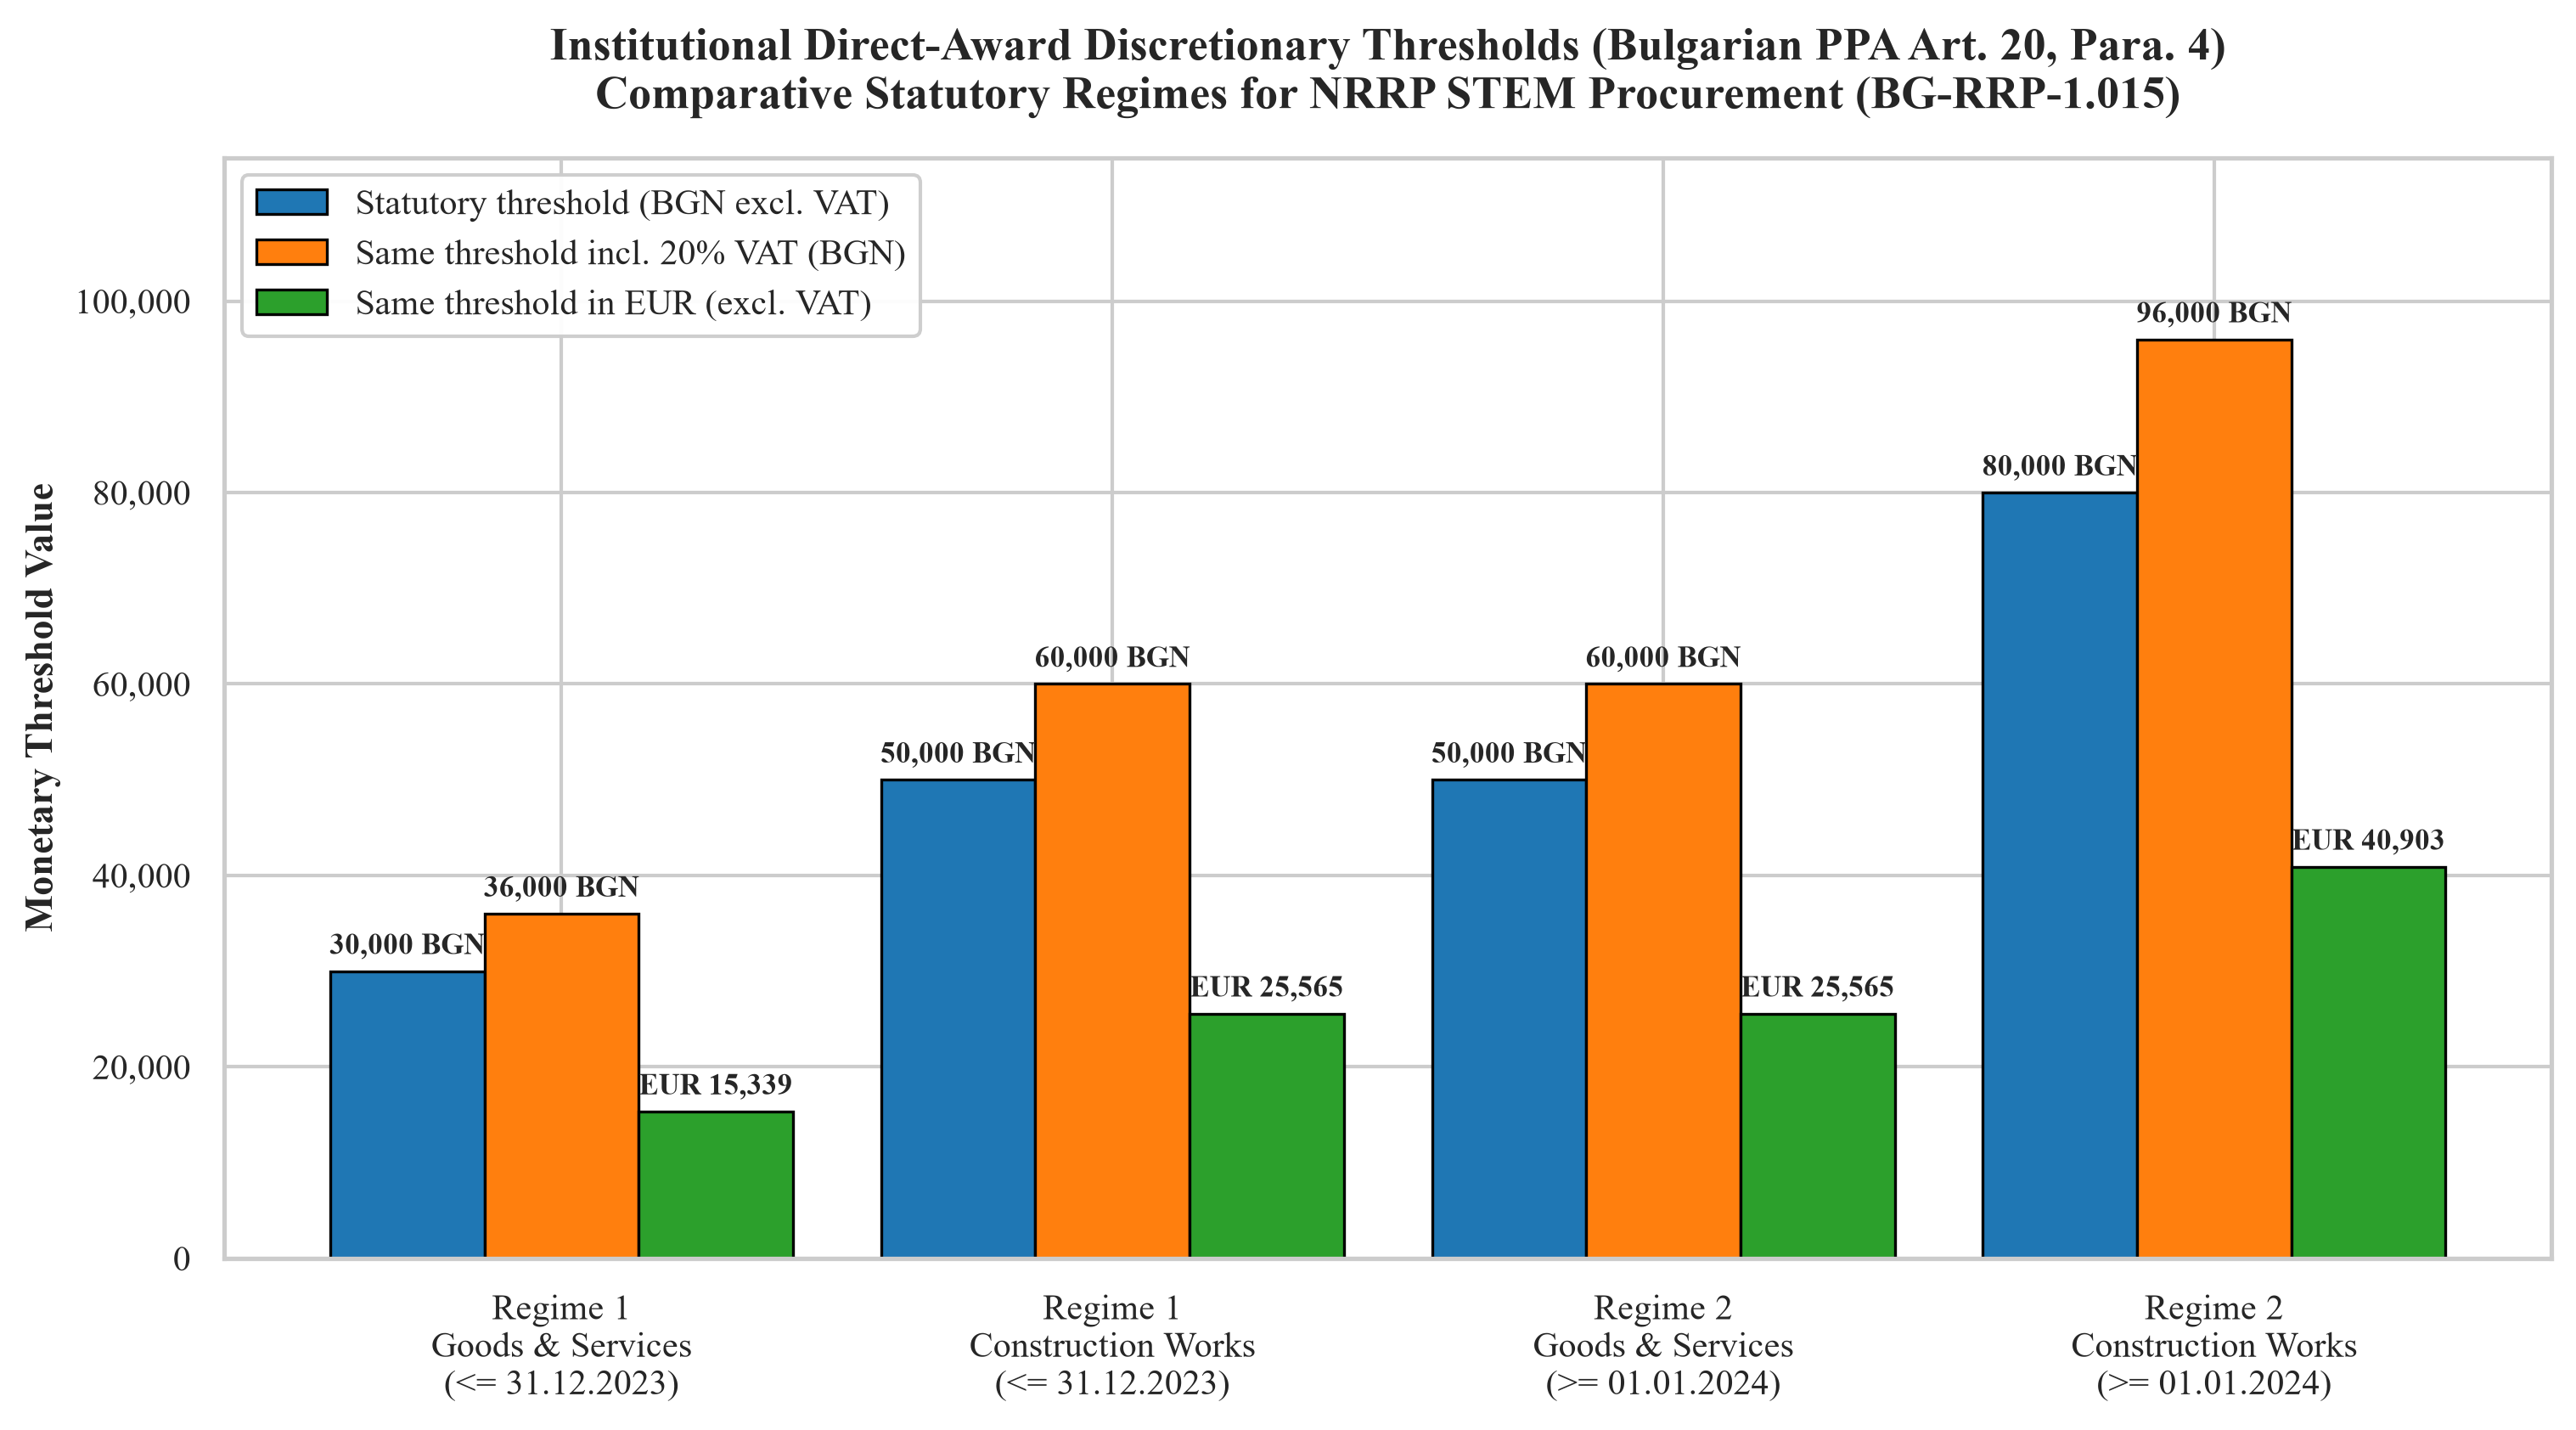

In [4]:
fig1, ax1 = plt.subplots(figsize=(10, 5.5), constrained_layout=True)

categories = [
    "Regime 1\nGoods & Services\n(<= 31.12.2023)",
    "Regime 1\nConstruction Works\n(<= 31.12.2023)",
    "Regime 2\nGoods & Services\n(>= 01.01.2024)",
    "Regime 2\nConstruction Works\n(>= 01.01.2024)",
]

net_bgn = [
    ThresholdConfig.T1_GOODS_SERVICES_NET_BGN,
    ThresholdConfig.T1_WORKS_NET_BGN,
    ThresholdConfig.T2_GOODS_SERVICES_NET_BGN,
    ThresholdConfig.T2_WORKS_NET_BGN,
]
gross_bgn = [v * (1 + ThresholdConfig.VAT_RATE) for v in net_bgn]
net_eur = [v / ThresholdConfig.EUR_BGN for v in net_bgn]

x = np.arange(len(categories))
width = 0.28

rects1 = ax1.bar(x - width, net_bgn, width, label="Statutory threshold (BGN excl. VAT)", color="#1f77b4", edgecolor="black", linewidth=0.8)
rects2 = ax1.bar(x, gross_bgn, width, label="Same threshold incl. 20% VAT (BGN)", color="#ff7f0e", edgecolor="black", linewidth=0.8)
rects3 = ax1.bar(x + width, net_eur, width, label="Same threshold in EUR (excl. VAT)", color="#2ca02c", edgecolor="black", linewidth=0.8)

ax1.set_ylabel("Monetary Threshold Value", fontweight="bold")
ax1.set_title("Institutional Direct-Award Discretionary Thresholds (Bulgarian PPA Art. 20, Para. 4)\nComparative Statutory Regimes for NRRP STEM Procurement (BG-RRP-1.015)", pad=14)
ax1.set_xticks(x)
ax1.set_xticklabels(categories, fontweight="normal")
ax1.legend(loc="upper left", frameon=True, facecolor="white", edgecolor="#cccccc", framealpha=0.95)
ax1.yaxis.set_major_formatter(ticker.FuncFormatter(lambda y, _: f"{int(y):,}"))
ax1.set_ylim(0, 115000)

def autolabel(rects, is_eur=False):
    for rect in rects:
        h = rect.get_height()
        label = f"EUR {h:,.0f}" if is_eur else f"{h:,.0f} BGN"
        ax1.annotate(label,
                    xy=(rect.get_x() + rect.get_width() / 2, h),
                    xytext=(0, 3),
                    textcoords="offset points",
                    ha="center", va="bottom", fontsize=8.5, rotation=0, fontweight="bold")

autolabel(rects1)
autolabel(rects2)
autolabel(rects3, is_eur=True)

plt.show()

**Figure 3.1.** Statutory direct-award thresholds for goods and services and for construction works under the two regimes, in net BGN, with their conversions to gross BGN and net EUR.

*Source:* Bulgaria (2016, Art. 20(4)) for contracts signed up to 31 December 2023; Bulgaria (2023, Art. 20(4)) for contracts signed from 1 January 2024.

### 3.2 Excess Mass Below a Discretionary Threshold

**Question.** If a contracting authority may award directly below a threshold, do contract values accumulate just under that threshold?

**Why a density with a counterfactual.** Contract values are expected to follow a smooth distribution. A threshold is a place where the legal consequences change abruptly, so a manipulation of values appears as a break in an otherwise smooth density. Contract values are compared with the density estimated for the case without the threshold (the counterfactual), and the difference just below the threshold is the excess mass, $B = \sum_j (c_j - \hat{c}_j)$, together with the missing mass above it (Palguta and Pertold, 2017).

**How to read.** The dashed blue line is the counterfactual density $\hat{c}(z)$. The solid red line is the observed density $c(z)$ with the bunching pattern. The hatched area is the excess mass $B$. The dotted vertical line is the threshold $T = 50\,000$ BGN net, which applies to construction works before 2024 and to goods and services from 2024.

**What the figure is not.** It is a stylised illustration of the method with illustrative values, not an estimate from the contract data. A concentration below a threshold is a warning sign that calls for an explanation, not proof of a violation.

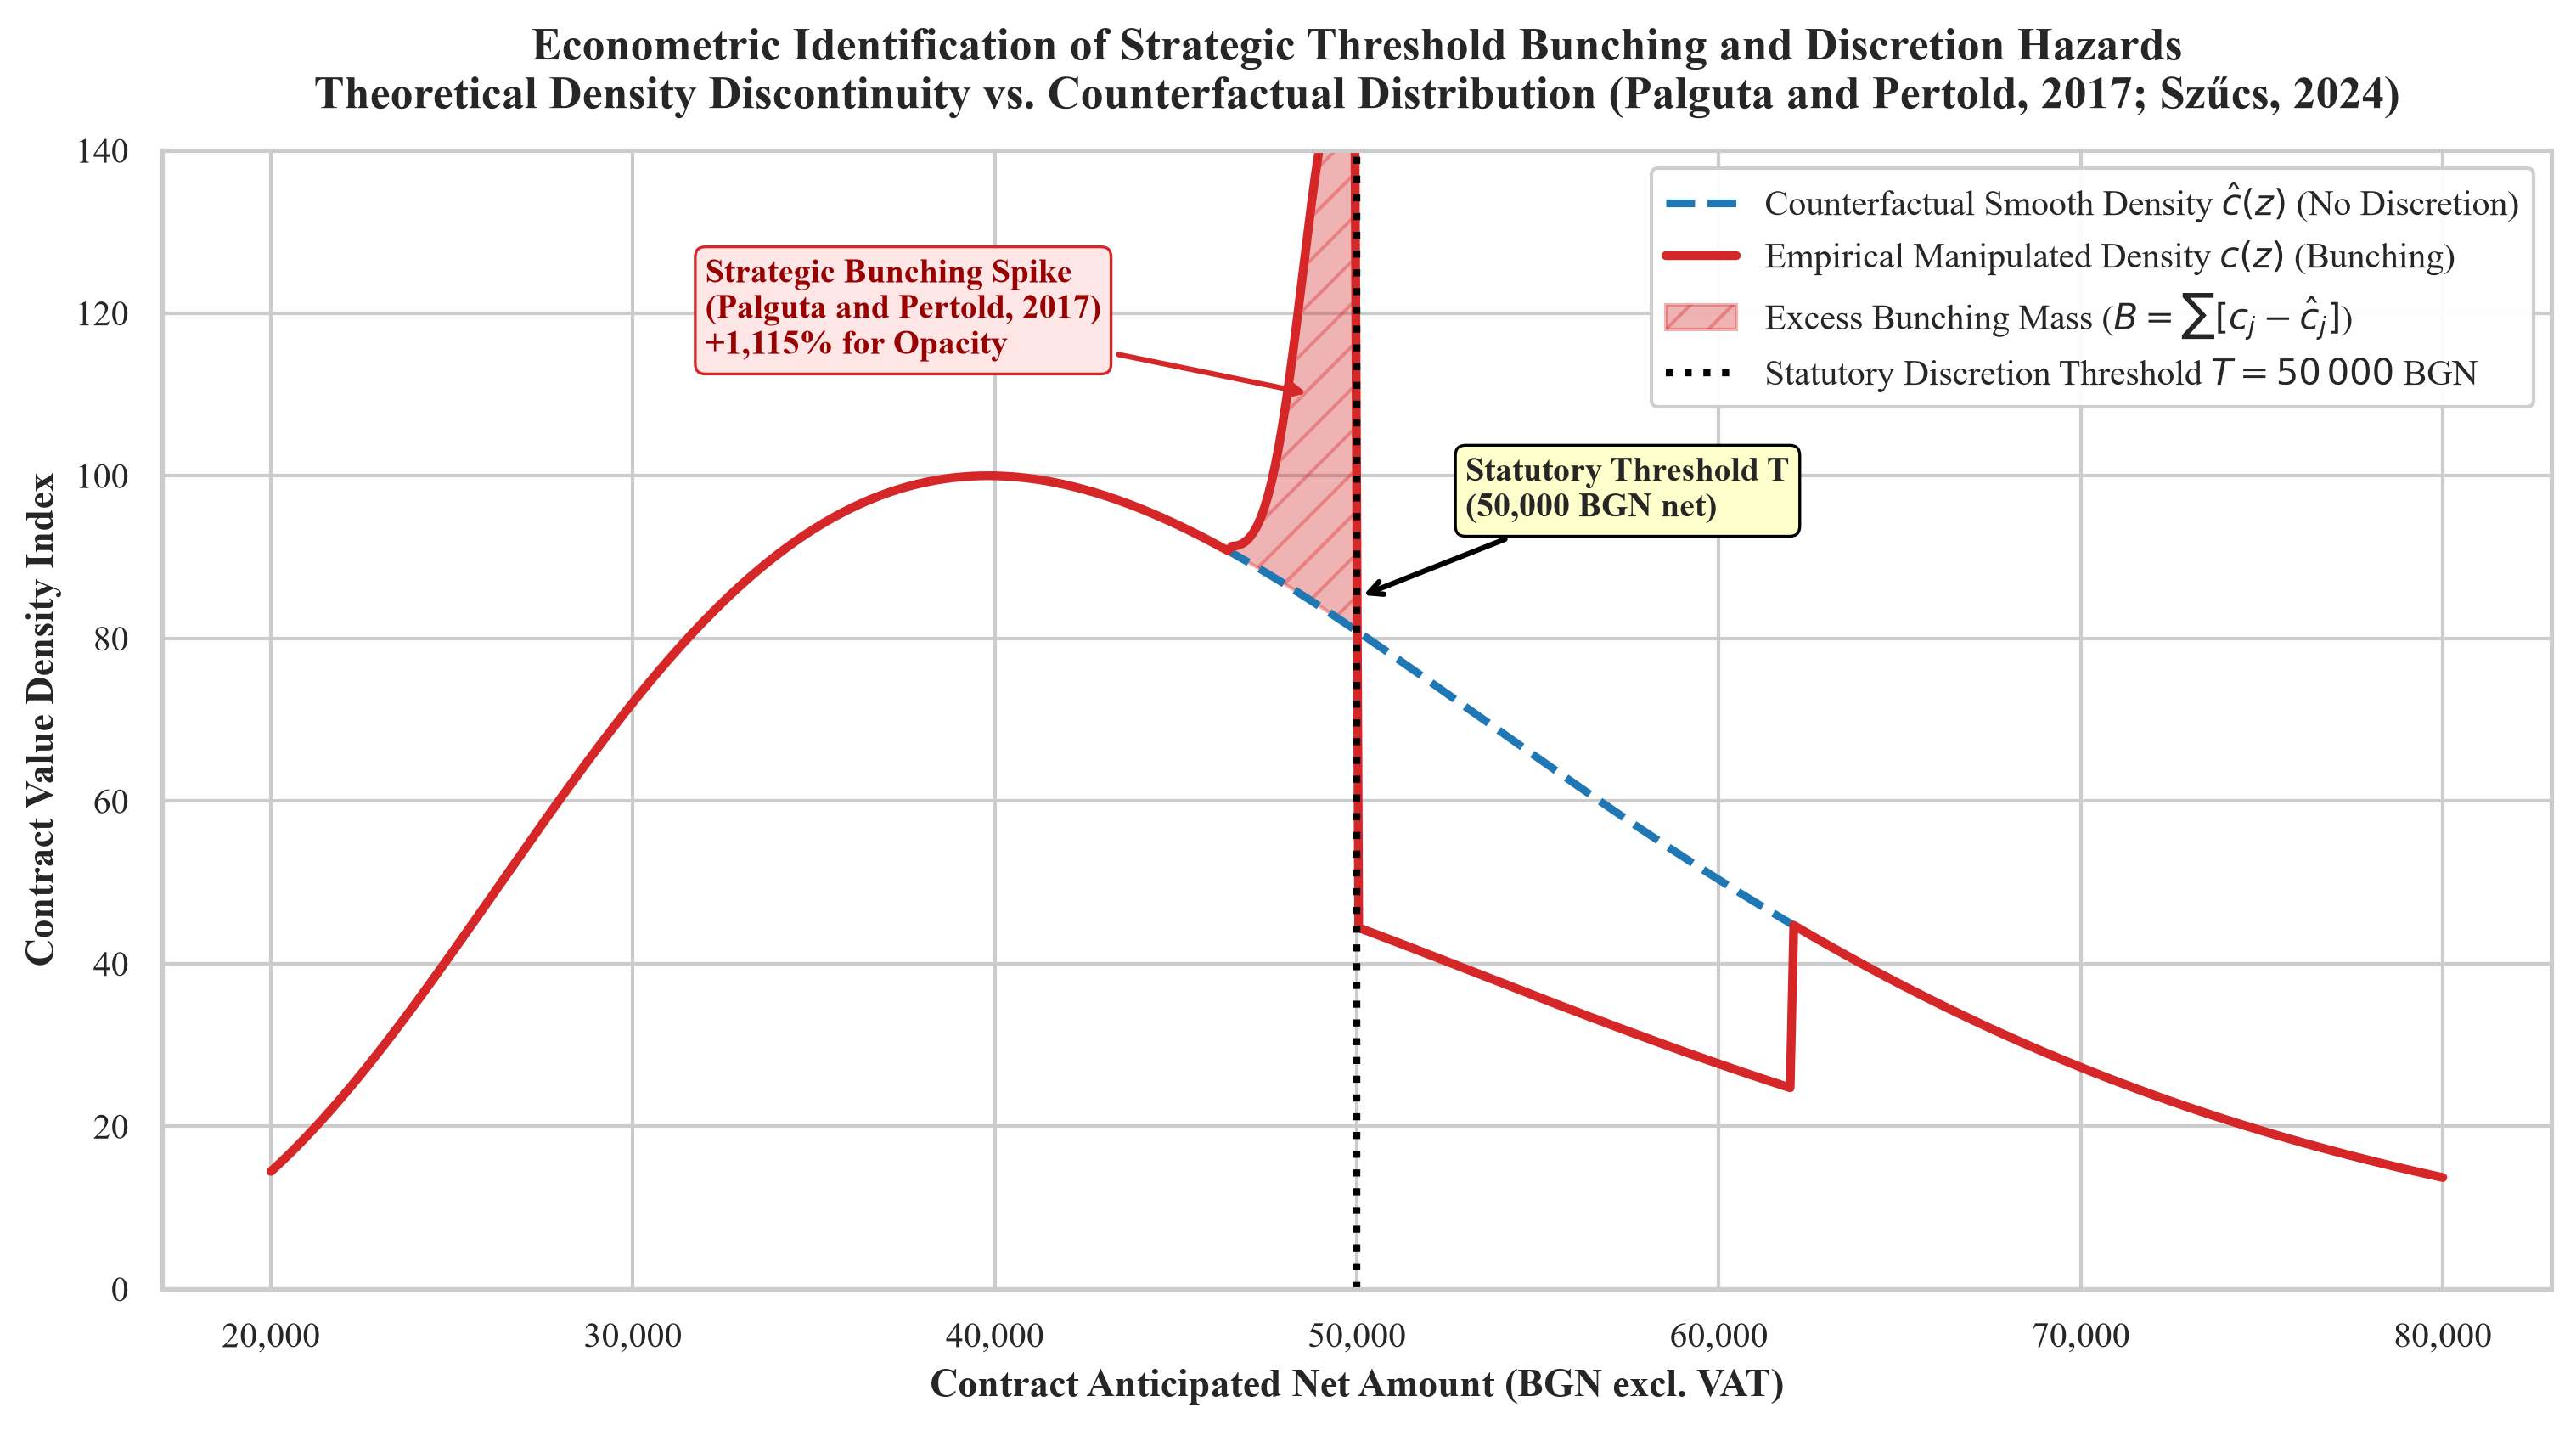

In [5]:
threshold_val = 50000.0  # Regime 1 Works / Regime 2 Goods threshold
v_axis = np.linspace(20000, 80000, 600)

# Counterfactual smooth log-normal distribution (unmanipulated market density)
mu, sigma = np.log(45000), 0.35
cf_density = (1 / (v_axis * sigma * np.sqrt(2 * np.pi))) * np.exp(-((np.log(v_axis) - mu)**2) / (2 * sigma**2))
cf_density = cf_density / np.max(cf_density) * 100.0  # Normalized index

# Empirical manipulated density with strategic bunching spike just below threshold (Palguta and Pertold, 2017)
manipulated_density = cf_density.copy()
above_mask = (v_axis >= threshold_val) & (v_axis <= threshold_val + 12000)
manipulated_density[above_mask] *= 0.55
bunch_mask = (v_axis >= threshold_val - 3500) & (v_axis < threshold_val)
manipulated_density[bunch_mask] += 65.0 * np.exp(-((v_axis[bunch_mask] - (threshold_val - 500))**2) / (2 * (1000**2)))

fig2, ax2 = plt.subplots(figsize=(10, 5.5), constrained_layout=True)

ax2.plot(v_axis, cf_density, color="#1f77b4", linestyle="--", linewidth=2.2, label=r"Counterfactual Smooth Density $\hat{c}(z)$ (No Discretion)")
ax2.plot(v_axis, manipulated_density, color="#d62728", linestyle="-", linewidth=2.5, label=r"Empirical Manipulated Density $c(z)$ (Bunching)")

ax2.fill_between(v_axis[bunch_mask], cf_density[bunch_mask], manipulated_density[bunch_mask],
                 color="#d62728", alpha=0.35, hatch="//", label=r"Excess Bunching Mass ($B = \sum [c_j - \hat{c}_j]$)")

ax2.axvline(threshold_val, color="black", linestyle=":", linewidth=2.0, label=r"Statutory Discretion Threshold $T = 50\,000$ BGN")
ax2.annotate(f"Statutory Threshold T\n({threshold_val:,.0f} BGN net)",
             xy=(threshold_val, 85), xytext=(threshold_val + 3000, 95),
             arrowprops=dict(arrowstyle="->", color="black", lw=1.5),
             fontsize=9.5, fontweight="bold", bbox=dict(boxstyle="round,pad=0.3", fc="#ffffcc", ec="black", lw=0.8))

ax2.annotate("Strategic Bunching Spike\n(Palguta and Pertold, 2017)\n+1,115% for Opacity",
             xy=(threshold_val - 1200, 110), xytext=(threshold_val - 18000, 115),
             arrowprops=dict(arrowstyle="->", color="#d62728", lw=1.5),
             fontsize=9.5, fontweight="bold", color="#990000",
             bbox=dict(boxstyle="round,pad=0.3", fc="#ffe6e6", ec="#d62728", lw=0.8))

ax2.set_xlabel("Contract Anticipated Net Amount (BGN excl. VAT)", fontweight="bold")
ax2.set_ylabel("Contract Value Density Index", fontweight="bold")
ax2.set_title("Econometric Identification of Strategic Threshold Bunching and Discretion Hazards\nTheoretical Density Discontinuity vs. Counterfactual Distribution (Palguta and Pertold, 2017; Szűcs, 2024)", pad=12)
ax2.legend(loc="upper right", frameon=True, facecolor="white", framealpha=0.95)
ax2.set_ylim(0, 140)
ax2.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f"{int(x):,}"))

plt.show()

**Figure 3.2.** Stylised density of contract values around a discretionary threshold, with the counterfactual density and the excess mass below the threshold (illustrative values).

*Source:* author's illustration based on Palguta and Pertold (2017).

### 3.3 Competition Around the Threshold

**Question.** Does discretion in the award go together with less competition?

**Why a line comparison of bidder numbers.** Discretionary awards go together with fewer competing bidders (Szűcs, 2024). If the contracting authority chooses whom to invite, the average number of bidders below the threshold should be lower than an open procedure would attract at the same contract value. A line plotted against the contract value shows whether such a gap exists and whether it appears exactly at the threshold, which is what separates the effect of the rule from the effect of contract size.

**How to read.** The dashed blue line is the number of bidders expected under an open procedure. The solid green line is the number under discretion, which drops at the threshold. The dotted vertical line is the threshold, as in the previous figure. An average close to one bidder below the threshold means that a single bidder is the typical outcome there.

**What the figure is not.** It is the same kind of stylised illustration with illustrative values and does not use the contract data. The ISUN records name only the winning supplier, so the number of bidders cannot be observed in this study. The figure shows the mechanism that the threshold test of Figure 3.2 detects indirectly.

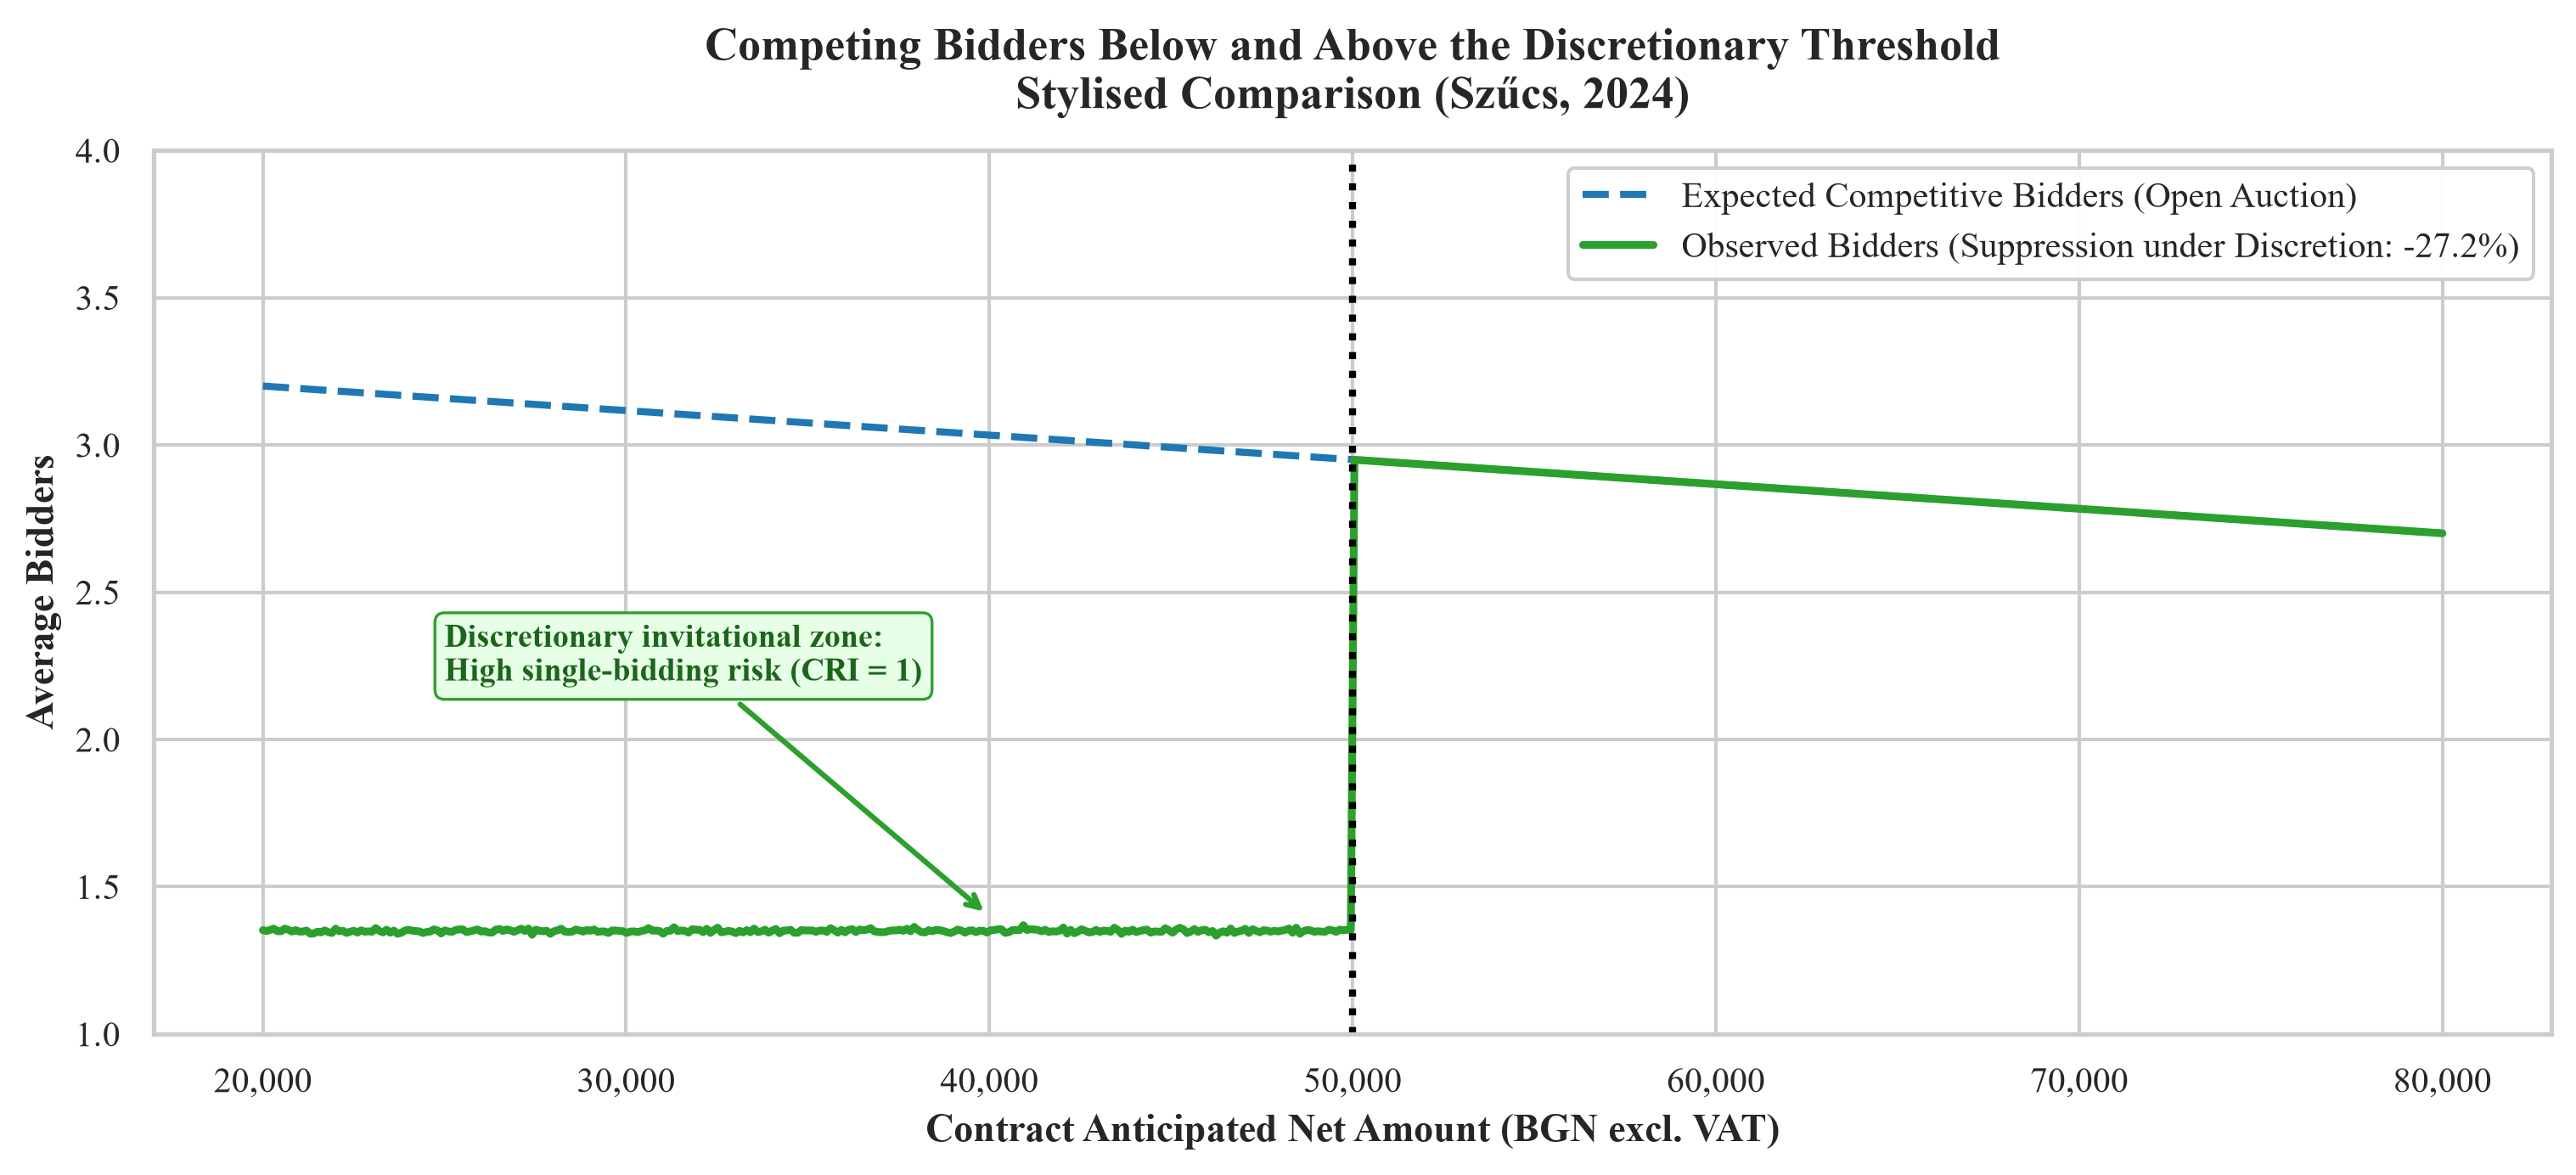

In [6]:
np.random.seed(ModelConfig.SEED)

# Number of competitive bidders (Szűcs, 2024; Palguta and Pertold, 2017)
bidders_cf = 3.2 - 0.5 * ((v_axis - 20000) / 60000)
bidders_obs = np.where(v_axis < threshold_val, 1.35 + 0.1 * np.random.normal(0, 0.05, len(v_axis)), bidders_cf)

fig3, ax3 = plt.subplots(figsize=(10, 4.5), constrained_layout=True)

ax3.plot(v_axis, bidders_cf, color="#1f77b4", linestyle="--", linewidth=2.0, label="Expected Competitive Bidders (Open Auction)")
ax3.plot(v_axis, bidders_obs, color="#2ca02c", linestyle="-", linewidth=2.2, label="Observed Bidders (Suppression under Discretion: -27.2%)")
ax3.axvline(threshold_val, color="black", linestyle=":", linewidth=2.0)

ax3.annotate("Discretionary invitational zone:\nHigh single-bidding risk (CRI = 1)",
             xy=(threshold_val - 10000, 1.4), xytext=(threshold_val - 25000, 2.2),
             arrowprops=dict(arrowstyle="->", color="#2ca02c", lw=1.5),
             fontsize=9.0, fontweight="bold", color="#1b661b",
             bbox=dict(boxstyle="round,pad=0.3", fc="#e6ffe6", ec="#2ca02c", lw=0.8))

ax3.set_xlabel("Contract Anticipated Net Amount (BGN excl. VAT)", fontweight="bold")
ax3.set_ylabel("Average Bidders", fontweight="bold")
ax3.set_title("Competing Bidders Below and Above the Discretionary Threshold\nStylised Comparison (Szűcs, 2024)", pad=12)
ax3.set_ylim(1.0, 4.0)
ax3.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f"{int(x):,}"))
ax3.legend(loc="upper right", frameon=True, facecolor="white", framealpha=0.95)

plt.show()

**Figure 3.3.** Stylised average number of competing bidders below and above a discretionary threshold (illustrative values).

*Source:* author's illustration based on Szűcs (2024).

## 4. Problem Formulation and Hypotheses

### 4.1 Institutional Setting and Four-Level Framework

Procedure BG-RRP-1.015 was carried out in a decentralised way. Each of the 2,228 projects was implemented by a school that acted as its own contracting authority under the Public Procurement Act, and the 11,128 contracts were awarded by many small buyers. Schools are not specialised in procurement, so the study asks whether outside actors shape which suppliers they choose. The framework below structures this question into four levels. Levels 2 and 3 are hypotheses that are tested for compatibility with the data. Levels 1 and 4 describe the funding and the available records.

1. **Funding and contracting authority.** Funds of the Recovery and Resilience Plan are coordinated by the Ministry of Education and Science and reach the schools, which award the contracts.
2. **Local and regional influence (hypothesis).** The 28 regional education directorates and the municipal authorities stand in a relation of administrative dependence to school principals. The hypothesis is that this relation is visible in the choice of suppliers within a region or a municipality.
3. **Supplier groups (hypothesis).** Consulting firms ($V_{\text{cons}}$) that prepare projects, suppliers of equipment ($V_{\text{tech}}$) and construction contractors ($V_{\text{civil}}$) may appear together at the same schools. The hypothesis is that consultancy contracts are signed before the supply and works contracts and are associated with the same suppliers.
4. **Audit record.** The records of ISUN 2020 and the audit reports of the State Financial Inspection Agency (ADFI) allow the risk indicators to be compared with the outcome of inspections, for example with penalty acts (*АУАН*) issued to school officials.

A statistical anomaly or a risk indicator is not evidence of a violation.

```mermaid
flowchart TD
    subgraph L1["1. Funding and contracting authority"]
        EU["Recovery and Resilience Plan funds"]
        MON["Ministry of Education and Science<br/>(coordinator)"]
        Schools["Schools<br/>(contracting authorities under the Public Procurement Act)"]
        EU --> MON --> Schools
    end
    subgraph L2["2. Local and regional influence (hypothesis)"]
        RUO["Regional education directorates<br/>(28 regions)"]
        Mayors["Municipal authorities"]
    end
    subgraph L3["3. Supplier groups (hypothesis)"]
        Consultants["Consulting firms V_cons<br/>(project preparation)"]
        Vendors["Equipment suppliers V_tech<br/>Construction contractors V_civil"]
    end
    subgraph L4["4. Audit record (data)"]
        ISUN["ISUN 2020 records<br/>(2,228 projects, 11,128 contracts)"]
        ADFI["ADFI audit reports<br/>(penalty acts to school officials)"]
    end
    RUO -->|administrative dependence| Schools
    Mayors -->|administrative dependence| Schools
    Consultants <-->|possible contact| RUO
    Consultants <-->|possible contact| Mayors
    Consultants <-->|shared suppliers, lift above 1| Vendors
    Consultants -->|contract dated before the supply contract| Schools
    Vendors -->|supply and works contracts| Schools
    Schools -.->|recorded in| ISUN
    Schools -.->|inspected in| ADFI
```

**Figure 4.1.** Four-level framework of the procedure. Levels 2 and 3 are hypotheses of this study, levels 1 and 4 describe funding and records.

*Source:* author's conceptual model.

### 4.2 Four Testable Hypotheses

Each hypothesis is stated so that the data can contradict it.

- **$H_1$ (degree confounding or turnkey groups).** In an uncorrected projection of the buyer-supplier network, suppliers with many buyers share buyers more often than chance implies, because the degrees differ. Under the bipartite configuration model, which fixes the degrees of buyers and suppliers (Saracco et al., 2017), $H_1$ asks whether this effect disappears and whether groups of suppliers remain whose overlap is statistically validated (Tumminello et al., 2011).
- **$H_2$ (consultant-steered bundling).** Contracts of consulting firms precede supply and works contracts at the same school ($t_{\text{cons}} \le t_{\text{supply}}$), and consulting firms and suppliers share schools more often than expected (lift well above 1; Coscia and Neffke, 2017).
- **$H_3$ (regional and municipal concentration).** Validated supplier groups and risk indicators are concentrated across regions and municipalities more than a stratified permutation null model implies (Wachs et al., 2021). The test separates the municipal level from the regional level.
- **$H_4$ (threshold bunching, contracts signed before the project start, and audit outcomes).** (a) Contract values accumulate just below the direct-award thresholds, 30,000 and 50,000 BGN before 2024 and 50,000 and 80,000 BGN from 2024 (Palguta and Pertold, 2017; Szűcs, 2024; Bulgaria, 2016; Bulgaria, 2023). (b) A contract signed before the start date of its project, as recorded in ISUN 2020, is a risk indicator. (c) These indicators are more frequent at schools whose ADFI audit led to a penalty act.

## 5. Mathematical Theory and Propositions

### 5.1 Bipartite Representation and Projection

Let $B = (U, V, E, W)$ be a weighted bipartite graph. $U = \{u_1, \dots, u_{N_U}\}$ is the set of $N_U = 2\,228$ schools and $V = \{v_1, \dots, v_{N_V}\}$ is the set of $N_V = 1\,755$ suppliers, which are divided into three functional subsets:
$$V = V_{\text{cons}} \cup V_{\text{tech}} \cup V_{\text{civil}}$$
The incidence matrix is $B \in \{0, 1\}^{N_U \times N_V}$ with elements $b_{i\alpha} \in \{0, 1\}$. The degrees are
$$k_i = \sum_{\alpha \in V} b_{i\alpha} \quad (\text{contract degree of school } i), \qquad d_\alpha = \sum_{i \in U} b_{i\alpha} \quad (\text{market degree of supplier } \alpha).$$
The one-mode projection onto suppliers is the Gram matrix of co-occurrence counts:
$$O = B^{T} B \in \mathbb{N}^{N_V \times N_V}, \qquad O_{\alpha\beta} = \sum_{i \in U} b_{i\alpha} b_{i\beta}.$$

### 5.2 Statistical Filtering and Null Models

**1. Hypergeometric null model (Tumminello et al., 2011).** If the buyers of two suppliers are drawn at random given the degrees $d_\alpha$ and $d_\beta$, the probability of at least $O_{\alpha\beta}$ shared schools is
$$P_{\text{Hyp}}(X \ge O_{\alpha\beta} \mid N_U, d_\alpha, d_\beta) = \sum_{k = O_{\alpha\beta}}^{\min(d_\alpha, d_\beta)} \frac{\binom{d_\alpha}{k} \binom{N_U - d_\alpha}{d_\beta - k}}{\binom{N_U}{d_\beta}}.$$
The $M = \binom{N_V}{2}$ pair tests are corrected with the Benjamini–Hochberg procedure at the level $\alpha_{\text{FDR}} = 0.01$ (Tumminello et al., 2011; Saracco et al., 2017).

**2. Bipartite configuration model, BiCM (Saracco et al., 2017).** The ensemble that maximises the Shannon entropy while it reproduces the degree sequences of both sets of nodes has the Hamiltonian
$$\mathcal{H}(B) = \sum_{i \in U} \theta_i k_i(B) + \sum_{\alpha \in V} \mu_\alpha d_\alpha(B)$$
and the independent connection probabilities
$$p_{i\alpha} = \frac{x_i y_\alpha}{1 + x_i y_\alpha}, \qquad x_i = e^{-\theta_i}, \quad y_\alpha = e^{-\mu_\alpha}.$$
The parameters $\vec{x}, \vec{y}$ solve the $N_U + N_V$ coupled equations
$$\sum_{\alpha \in V} \frac{x_i y_\alpha}{1 + x_i y_\alpha} = k_i \;\; \forall i \in U, \qquad \sum_{i \in U} \frac{x_i y_\alpha}{1 + x_i y_\alpha} = d_\alpha \;\; \forall \alpha \in V.$$
The co-occurrence $V_{\alpha\beta} = \sum_i b_{i\alpha} b_{i\beta}$ is a sum of independent Bernoulli variables with parameters $\pi_{i} = p_{i\alpha} p_{i\beta}$, so it follows a Poisson-binomial distribution. Its survival function is evaluated exactly with the discrete Fourier transform of the characteristic function,
$$\phi_{\alpha\beta}(t) = \prod_{i=1}^{N_U} \left[ (1 - \pi_i) + \pi_i e^{\mathrm{i} t} \right], \qquad t_l = \frac{2\pi l}{N_U + 1}, \; l = 0, \dots, N_U.$$
The Poisson approximation is acceptable only when Le Cam's inequality gives a small bound (Saracco et al., 2017):
$$\sum_{k} \left| f_{\text{PB}}(k) - f_{\text{Poisson}}(k) \right| < 2 \sum_{i=1}^{N_U} \pi_i^2.$$

**3. Disparity filter on the co-occurrence counts (the baseline described by Coscia and Neffke, 2017).**
$$\alpha_{\alpha\beta} = \left( 1 - \frac{O_{\alpha\beta}}{s_\alpha} \right)^{k_\alpha - 1}, \qquad s_\alpha = \sum_{\beta \ne \alpha} O_{\alpha\beta}, \qquad k_\alpha = \left| \{ \beta \ne \alpha : O_{\alpha\beta} > 0 \} \right|.$$
A link is kept if $\min(\alpha_{\alpha\beta}, \alpha_{\beta\alpha}) < \alpha_{\text{DF}}$.

**4. Noise-corrected backbone (Coscia and Neffke, 2017).** For the weights $N_{ij} = O_{ij}$ with strengths $N_{i\cdot} = \sum_{j \ne i} O_{ij}$, $N_{\cdot j} = \sum_{i \ne j} O_{ij}$ and total $N_{\cdot\cdot} = \sum_i N_{i\cdot}$, the expected weight, the transformed lift and its variance by the delta method are
$$\mathbb{E}[N_{ij}] = \frac{N_{i\cdot} N_{\cdot j}}{N_{\cdot\cdot}}, \qquad \kappa = \frac{N_{\cdot\cdot}}{N_{i\cdot} N_{\cdot j}}, \qquad \tilde{L}_{ij} = \frac{\kappa N_{ij} - 1}{\kappa N_{ij} + 1},$$
$$\mathbb{V}[\tilde{L}_{ij}] = \mathbb{V}[N_{ij}] \left( \frac{2 \left( \kappa + N_{ij} \frac{d\kappa}{dN_{ij}} \right)}{(\kappa N_{ij} + 1)^2} \right)^2, \qquad \frac{d\kappa}{dN_{ij}} = \frac{1}{N_{i\cdot} N_{\cdot j}} - \frac{N_{\cdot\cdot} (N_{i\cdot} + N_{\cdot j})}{(N_{i\cdot} N_{\cdot j})^2}.$$
The variance is $\mathbb{V}[N_{ij}] = N_{\cdot\cdot} P_{ij} (1 - P_{ij})$ with $P_{ij} \sim \text{Beta}(N_{ij} + \alpha, N_{\cdot\cdot} - N_{ij} + \beta)$. The prior is fitted to the hypergeometric moments,
$$\mu = \frac{N_{i\cdot} N_{\cdot j}}{N_{\cdot\cdot}^2}, \quad \sigma^2 = \frac{N_{i\cdot} N_{\cdot j} (N_{\cdot\cdot} - N_{i\cdot}) (N_{\cdot\cdot} - N_{\cdot j})}{N_{\cdot\cdot}^4 (N_{\cdot\cdot} - 1)}, \quad \alpha = \frac{\mu^2}{\sigma^2} (1 - \mu) - \mu, \quad \beta = \mu \left( \frac{(1 - \mu)^2}{\sigma^2} + 1 \right) - 1,$$
and the posterior mean $\mathbb{E}[P_{ij}] = (N_{ij} + \alpha) / (N_{\cdot\cdot} + \alpha + \beta)$ is used. A link is kept if $\tilde{L}_{ij} > \delta \sqrt{\mathbb{V}[\tilde{L}_{ij}]}$, where $\delta = 2.32$ corresponds to $p \approx 0.01$.

**5. Lift for directed association (Coscia and Neffke, 2017).** For a consulting firm $\alpha$ and a supplier $\beta$,
$$\text{Lift}(\alpha, \beta) = \frac{P(\alpha \cap \beta)}{P(\alpha) P(\beta)} = \frac{M_{\text{steer}}(\alpha, \beta) \, N_U}{d_\alpha d_\beta},$$
where $M_{\text{steer}}(\alpha, \beta)$ is the number of schools at which both firms appear and the contract of $\alpha$ is dated no later than the contract of $\beta$.

**6. Modularity and communities (Wachs et al., 2021).** With the validated adjacency matrix $A^{\text{val}}$, total weight $2m$ and resolution $\gamma$,
$$Q = \frac{1}{2m} \sum_{\alpha, \beta} \left[ A^{\text{val}}_{\alpha\beta} - \gamma \frac{d^{\text{val}}_\alpha d^{\text{val}}_\beta}{2m} \right] \delta(c_\alpha, c_\beta).$$

**7. Coherence and exclusivity of a group $G$ (Wachs and Kertész, 2019).** With $l_G$ the set of internal links of $G$ with $O_{\alpha\beta} > 0$ and $m_G = |l_G|$,
$$C_G = \frac{\left( \prod_{l \in l_G} O_l \right)^{1 / m_G}}{\frac{1}{m_G} \sum_{l \in l_G} O_l}, \qquad E_G = \frac{s_{\text{in}}^G}{s_{\text{in}}^G + s_{\text{out}}^G},$$
$$s_{\text{in}}^G = \sum_{\alpha < \beta \in G} O_{\alpha\beta}, \qquad s_{\text{out}}^G = \sum_{\alpha \in G} \sum_{\gamma \notin G} O_{\alpha\gamma}.$$
Both lie in $[0, 1]$. A group with $C_G$ near 1 has uniform internal ties, and a group with $E_G$ near 1 has almost no ties to the rest of the market.

**8. Stratified permutation null model (after Wachs et al., 2021).** Wachs et al. (2021) shuffle the flags within sectors. Here the labels are permuted within regions, so the test statistic $\Delta T$ is compared with its permutation distribution at equal regional composition:
$$p_{\text{strat}} = \frac{1 + \sum_{\pi=1}^{K} \mathbb{I}\left[ \Delta T^{(\pi)} \ge \Delta T^{\text{obs}} \right]}{K + 1}.$$

**9. Weighted $k$-shell decomposition (Wachs et al., 2021).** Nodes are removed iteratively by their strength $s_\alpha = \sum_i W_{i\alpha}$, the total contracted value, which gives the core-periphery position of a supplier without a bias towards the degree.

### 5.3 Indicators on Contract Values

**10. Bunching below a threshold (Palguta and Pertold, 2017; Szűcs, 2024).** The number of contracts $Y_{zt}$ in the value bin $z$ and period $t$ is modelled by Poisson quasi-maximum likelihood with
$$\mathbb{E}[Y_{zt}] = \exp\left( \alpha_z + \alpha_t + \beta_1 \, \text{Below}_z \times \text{Regime2}_t \right), \qquad \%\Delta = \left[ \exp(\beta_1) - 1 \right] \times 100\%,$$
where $\text{Below}_z$ marks the bins just below a threshold and $\text{Regime2}_t$ the period from 1 January 2024. With a counterfactual density $\hat{h}$ and the observed counts $C_j$, the excess mass below the threshold $T$ and the missing mass above it are
$$B = \sum_{j \in [T - \delta, T)} \left( C_j - \hat{h}(z_j) \right), \qquad M_{\text{missing}} = \sum_{j \in [T, T + \delta)} \left( \hat{h}(z_j) - C_j \right).$$

**11. Benford deviation of the spacings (Miller and Nigrini, 2006).** For the normalised spacings $Z$ of the ordered contract values and the mantissas $Y = \log_{10} Z \bmod 1$ with empirical distribution function $F_N$,
$$D_{\text{Benford}} = \sup_{b \in [0, 1)} \left| F_N(b) - b \right|.$$

**12. Same-day splitting index (operationalising the red flag in OECD, 2016).** For the set of contracts $\text{Contracts}(i, t)$ of buyer $i$ with one supplier on day $t$ and the threshold $T$,
$$S_{\text{same-day}}(i, t) = \sum_{k \in \text{Contracts}(i, t)} \mathbb{I}\left[ \text{Value}_k < T \right] \cdot \mathbb{I}\left[ \sum_{k} \text{Value}_k \ge T \right].$$
It counts the contracts below $T$ in a same-day set whose total reaches $T$.

**13. Enrichment of contracts signed before the project start (hypergeometric test after Tumminello et al., 2011).** Among $N_{\text{total}}$ contracts, $K_{\text{predated}}$ are signed before the start date of the project ($\Delta t < 0$). Supplier $\alpha$ has $n_\alpha$ contracts, $k_\alpha$ of them signed before the start, and
$$p_\alpha^{\Delta t} = \sum_{x = k_\alpha}^{\min(n_\alpha, K_{\text{predated}})} \frac{\binom{K_{\text{predated}}}{x} \binom{N_{\text{total}} - K_{\text{predated}}}{n_\alpha - x}}{\binom{N_{\text{total}}}{n_\alpha}}.$$

### 5.4 Propositions

#### Proposition 1: Degree Confounding in Uncorrected Projections

**Statement.** *Assume a sparse regime with $p_{i\alpha} \approx x_i y_\alpha \ll 1$. The expected co-occurrence of two suppliers then satisfies*
$$\mathbb{E}[O_{\alpha\beta}] = \sum_{i \in U} p_{i\alpha} p_{i\beta} \approx y_\alpha y_\beta \sum_{i \in U} x_i^2 = \frac{d_\alpha d_\beta}{N_U} \left( 1 + \frac{\mathrm{Var}(x)}{\bar{x}^2} \right) \ge \frac{d_\alpha d_\beta}{N_U},$$
*with strict inequality whenever the school propensities $x_i$ differ.*

**Proof.**
1. In the sparse regime $p_{i\alpha} = \dfrac{x_i y_\alpha}{1 + x_i y_\alpha} \approx x_i y_\alpha$.
2. The expected degree of supplier $\alpha$ is $d_\alpha = \sum_i p_{i\alpha} \approx y_\alpha \sum_i x_i$, so $y_\alpha \approx d_\alpha / \sum_i x_i$.
3. The expected co-occurrence is $\sum_i p_{i\alpha} p_{i\beta} \approx y_\alpha y_\beta \sum_i x_i^2$.
4. Substituting $y_\alpha$ and $y_\beta$ gives
$$\mathbb{E}[O_{\alpha\beta}] \approx \frac{d_\alpha d_\beta}{N_U} \cdot \frac{\frac{1}{N_U} \sum_i x_i^2}{\left( \frac{1}{N_U} \sum_i x_i \right)^2} = \frac{d_\alpha d_\beta}{N_U} \left( 1 + \frac{\mathrm{Var}(x)}{\bar{x}^2} \right).$$
5. By the Cauchy–Schwarz inequality, $\left( \sum_i x_i \right)^2 \le N_U \sum_i x_i^2$, with equality if and only if all $x_i$ are equal. Hence $\mathrm{Var}(x) \ge 0$ and the factor in step 4 is at least 1. $\blacksquare$

**Consequence.** The urn expectation $d_\alpha d_\beta / N_U$ underestimates the expected overlap when schools differ in activity. Two suppliers with many contracts therefore share schools more often than the urn model predicts, without any coordination. The bipartite configuration model corrects for this.

#### Theorem 1: False Discovery Control of the Benjamini–Hochberg Procedure

**Statement.** *Let $p_{(1)} \le \dots \le p_{(M)}$ be the sorted $p$-values of $M$ hypotheses, of which $m_0$ are true nulls, and let*
$$k^* = \max \left\{ k : p_{(k)} \le \frac{k}{M} \alpha \right\}.$$
*If the hypotheses $H_{(1)}, \dots, H_{(k^*)}$ are rejected and the $p$-values of the true nulls are independent, then*
$$\mathbb{E}[\mathrm{FDP}] = \mathbb{E}\left[ \frac{V}{\max(R, 1)} \right] = \frac{m_0}{M} \alpha \le \alpha,$$
*where $V$ is the number of false rejections and $R = k^*$ the number of all rejections.*

This is the procedure that Tumminello et al. (2011) and Saracco et al. (2017) apply to the pair tests. The pair hypotheses are not independent (Saracco et al., 2017), so the bound is an assumption for the network tests. The Bonferroni level $\alpha / M$ is reported as the conservative alternative (Tumminello et al., 2011). Section 6.2 checks the statement by simulation.

#### Proposition 2: Identification of Bunching and Missing Mass

**Statement.** *Let $f(z)$ be the density of contract values and $T$ a threshold below which the buyer may award directly. Let $h(z)$ be the counterfactual density without discretion, which is smooth on $[T - \delta, T + \delta]$. The excess mass $B$ and the missing mass $M_{\text{missing}}$,*
$$B = \int_{T - \delta}^{T} \left[ f(z) - h(z) \right] dz, \qquad M_{\text{missing}} = \int_{T}^{T + \delta} \left[ h(z) - f(z) \right] dz,$$
*are identified by fitting $h$ to the bins outside the manipulation window (Palguta and Pertold, 2017; Szűcs, 2024).* If contracts only move from just above to just below the threshold, $B = M_{\text{missing}}$. Section 6.7 checks that the estimator recovers a known shift.

#### Theorem 2: Spacings of Ordered Values and Benford's Law

**Statement (Miller and Nigrini, 2006).**
1. *A sequence is Benford in base $B$ if and only if its base-$B$ logarithms are equidistributed modulo 1.*
2. *If $X_1, \dots, X_N$ are drawn from the uniform distribution on $[0, L]$, the normalised spacings $Z_i = (X_{i+1:N} - X_{i:N}) / (L / N)$ converge to independent standard exponential variables as $N \to \infty$.*
3. *The digits of a standard exponential variable are very close to Benford's law. Miller and Nigrini give the maximum discrepancy as lying between $0.029$ and $0.030$.*

**Proof sketch of part 3.** The distribution function of $\log_B \zeta \bmod 1$ for $\zeta \sim \text{Exp}(1)$ is $F_B(b) = \sum_{k \in \mathbb{Z}} \left( e^{-B^k} - e^{-B^{b+k}} \right)$. Poisson summation gives the density
$$F'_B(b) = 1 + 2 \sum_{m=1}^{\infty} \mathrm{Re}\left( e^{-2\pi \mathrm{i} m b} \, \Gamma\left( 1 + \frac{2\pi \mathrm{i} m}{\ln B} \right) \right).$$
Since $|\Gamma(1 + \mathrm{i}x)|^2 = \pi x / \sinh(\pi x)$, the harmonics decay exponentially. For $B = 10$ the first harmonic has amplitude $r_1 \approx 0.0570$ and the second $r_2 \approx 0.0011$, which bounds the deviation from a uniform mantissa. $\blacksquare$

**Use.** A departure of the digits of the spacings from this pattern is a signal that the values are rounded or otherwise regular. It is a risk indicator, not proof of manipulation. Section 6.6 evaluates the series numerically.

## 6. Numerical Verification of the Propositions

Each proposition and method of Section 5 is checked on simulated data with a known structure. The checks do not use the contract data. They show that the code of the later steps reproduces the stated properties, and each ends with an assertion.

### 6.1 Degree Confounding (Proposition 1)

**Question.** Do two suppliers share more schools than the urn expectation $d_\alpha d_\beta / N_U$ when schools differ in activity?

**Why two panels.** Panel A compares the two expected overlaps pair by pair against the product of the supplier degrees. Panel B shows their ratio, which Proposition 1 puts at about $1 + \mathrm{Var}(x)/\bar{x}^2$.

**How to read.** Points above the dashed line in panel A, and above 1 in panel B, are pairs whose BiCM expectation exceeds the urn expectation.

**What the figure is not.** It is a simulation with heavy-tailed propensities of 500 schools and 200 suppliers, not an estimate from the contract data.

In [7]:
def verify_proposition_1(
    num_schools: int = 500,
    num_vendors: int = 200,
    alpha_school: float = 2.2,
    alpha_vendor: float = 1.8,
    seed: int = ModelConfig.SEED,
) -> dict[str, float | bool | np.ndarray]:
    """Compare the BiCM expected co-occurrence with the urn expectation d_a * d_b / N_U.

    With heterogeneous school propensities x_i, the expected co-occurrence
    sum_i p_ia * p_ib exceeds d_a * d_b / N_U (Saracco et al., 2017).
    """
    rng = np.random.default_rng(seed)

    # Heavy-tailed propensities of schools and suppliers
    school_propensity = rng.pareto(a=alpha_school, size=num_schools) + 1.0
    vendor_propensity = rng.pareto(a=alpha_vendor, size=num_vendors) + 1.0
    scale = 0.04 / np.sqrt(np.mean(school_propensity) * np.mean(vendor_propensity))
    x = school_propensity * scale
    y = vendor_propensity * scale

    # BiCM connection probabilities p_ia = x_i y_a / (1 + x_i y_a)
    outer_xy = np.outer(x, y)
    p = outer_xy / (1.0 + outer_xy)
    vendor_degree = p.sum(axis=0)

    expected_bicm = p.T @ p
    expected_urn = np.outer(vendor_degree, vendor_degree) / num_schools

    # Cauchy-Schwarz: sum(x^2) >= (sum x)^2 / N_U
    sum_x_sq = float(np.sum(x**2))
    cs_rhs = float(np.sum(x) ** 2 / num_schools)
    inflation_factor = 1.0 + float(np.var(x) / np.mean(x) ** 2)

    off_diagonal = ~np.eye(num_vendors, dtype=bool)
    ratio = expected_bicm[off_diagonal] / expected_urn[off_diagonal]

    assert sum_x_sq >= cs_rhs, "Cauchy-Schwarz inequality violated."
    assert np.all(ratio >= 1.0 - 1e-9), "Urn expectation exceeds the BiCM expectation for some pair."

    return {
        "num_schools": num_schools,
        "num_vendors": num_vendors,
        "sum_x_sq": sum_x_sq,
        "cs_rhs": cs_rhs,
        "cs_gap": sum_x_sq - cs_rhs,
        "inflation_factor": inflation_factor,
        "mean_ratio": float(np.mean(ratio)),
        "min_ratio": float(np.min(ratio)),
        "vendor_degree": vendor_degree,
        "expected_bicm": expected_bicm,
        "expected_urn": expected_urn,
    }


res_p1 = verify_proposition_1()
print(f"Schools: {res_p1['num_schools']} | Suppliers: {res_p1['num_vendors']}")
print(f"Sum of x_i^2:                      {res_p1['sum_x_sq']:.6f}")
print(f"(Sum of x_i)^2 / N_U:              {res_p1['cs_rhs']:.6f}")
print(f"Cauchy-Schwarz gap:                {res_p1['cs_gap']:.6f}")
print(f"Factor 1 + Var(x) / mean(x)^2:     {res_p1['inflation_factor']:.3f}")
print(f"Mean ratio BiCM / urn expectation: {res_p1['mean_ratio']:.3f}")
print(f"Minimum ratio over all pairs:      {res_p1['min_ratio']:.3f}")

Schools: 500 | Suppliers: 200
Sum of x_i^2:                      1.017613
(Sum of x_i)^2 / N_U:              0.638078
Cauchy-Schwarz gap:                0.379535
Factor 1 + Var(x) / mean(x)^2:     1.595
Mean ratio BiCM / urn expectation: 1.586
Minimum ratio over all pairs:      1.545


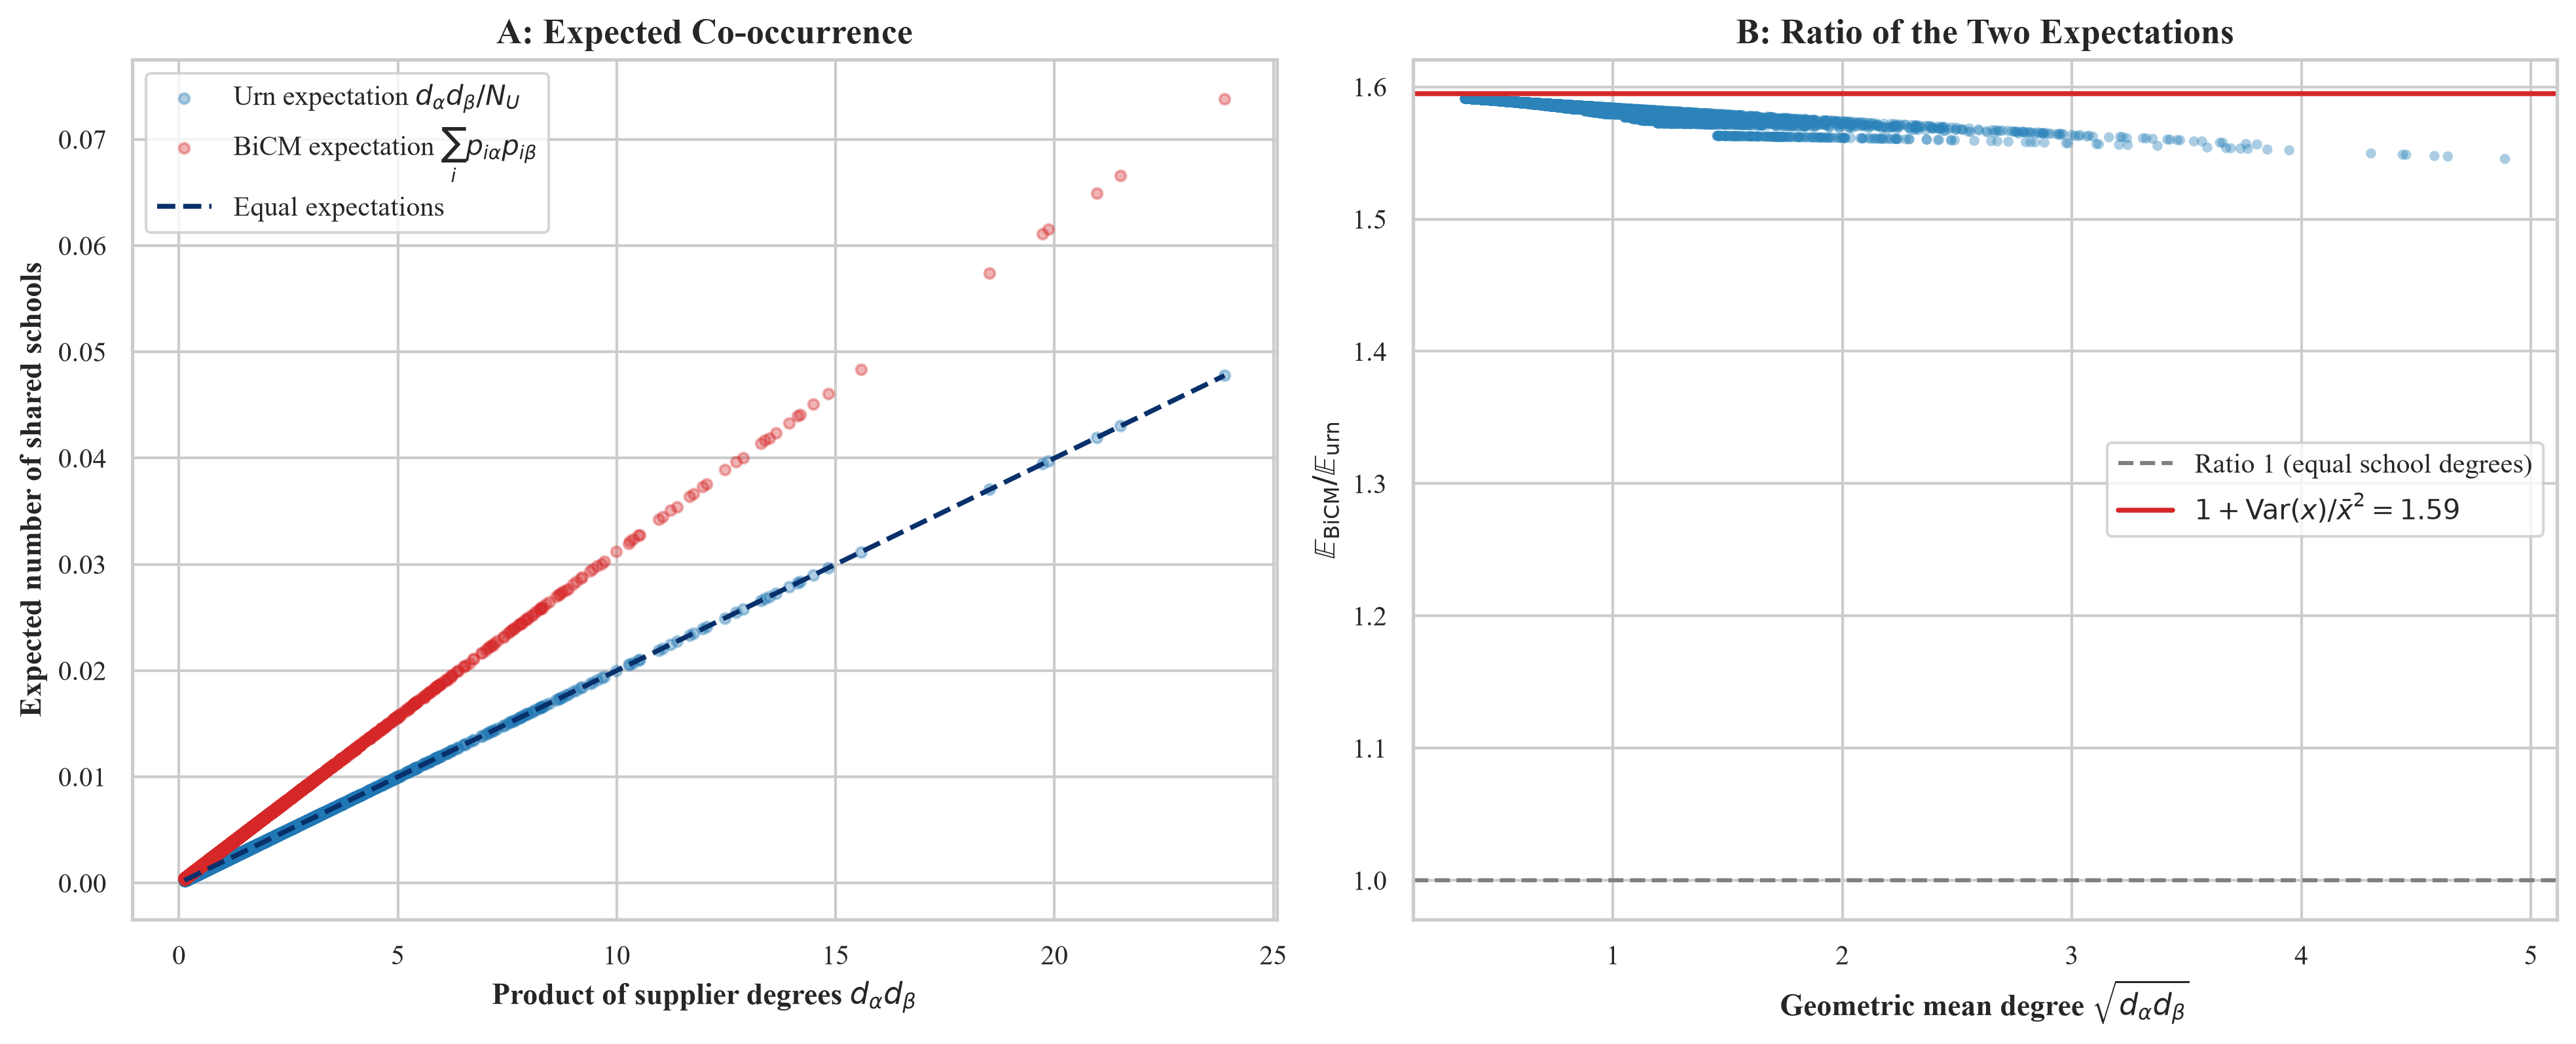

In [8]:
fig61, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.2), constrained_layout=True)

degree_product = np.outer(res_p1["vendor_degree"], res_p1["vendor_degree"])
upper = np.triu(np.ones_like(degree_product, dtype=bool), k=1)
x_vals = degree_product[upper]
y_bicm = res_p1["expected_bicm"][upper]
y_urn = res_p1["expected_urn"][upper]
n_schools = res_p1["num_schools"]

ax1.scatter(x_vals, y_urn, alpha=0.35, s=14, color="#1f77b4", label=r"Urn expectation $d_\alpha d_\beta / N_U$")
ax1.scatter(x_vals, y_bicm, alpha=0.35, s=14, color="#d62728", label=r"BiCM expectation $\sum_i p_{i\alpha} p_{i\beta}$")
grid = np.linspace(x_vals.min(), x_vals.max(), 200)
ax1.plot(grid, grid / n_schools, color="#08306b", linestyle="--", linewidth=1.8, label="Equal expectations")
ax1.set_title("A: Expected Co-occurrence")
ax1.set_xlabel(r"Product of supplier degrees $d_\alpha d_\beta$")
ax1.set_ylabel(r"Expected number of shared schools")
ax1.legend(loc="upper left", frameon=True)

ratio = y_bicm / y_urn
ax2.scatter(np.sqrt(x_vals), ratio, alpha=0.4, s=14, color="#2b83ba", edgecolors="none")
ax2.axhline(1.0, color="gray", linestyle="--", linewidth=1.5, label="Ratio 1 (equal school degrees)")
ax2.axhline(res_p1["inflation_factor"], color="#d62728", linewidth=1.8,
            label=rf"$1 + \mathrm{{Var}}(x)/\bar{{x}}^2 = {res_p1['inflation_factor']:.2f}$")
ax2.set_title("B: Ratio of the Two Expectations")
ax2.set_xlabel(r"Geometric mean degree $\sqrt{d_\alpha d_\beta}$")
ax2.set_ylabel(r"$\mathbb{E}_{\mathrm{BiCM}} / \mathbb{E}_{\mathrm{urn}}$")
ax2.legend(loc="center right", frameon=True)

plt.show()

**Figure 6.1.** Expected co-occurrence of supplier pairs under the BiCM and under the urn model (panel A) and the ratio of the two (panel B) in a simulated network.

*Source:* author's simulation based on Saracco et al. (2017).

### 6.2 False Discovery Control (Theorem 1)

**Question.** Does the Benjamini–Hochberg procedure keep the false discovery proportion below the level $\alpha$ when many pair hypotheses are tested?

**Why the sorted $p$-values.** The procedure rejects every hypothesis up to the largest rank at which the sorted $p$-value lies below the line $k\alpha/M$. The plot of the sorted $p$-values against this line shows the cut-off directly.

**How to read.** The green area is between the $p$-values and the BH line up to the cut-off $k^*$ and marks the validated links. Panel B enlarges the region around $k^*$. The printed mean over repeated draws is compared with the bound $(m_0/M)\alpha$.

**What the figure is not.** It is a simulation of 10,000 tests with 80% true nulls, not a test of the supplier pairs.

In [9]:
def verify_theorem_1_fdr(
    num_tests: int = 10000,
    pi_zero: float = 0.80,
    nominal_fdr: float = ModelConfig.ALPHA_FDR,
    replications: int = 200,
    seed: int = ModelConfig.SEED,
) -> dict[str, float | int | bool | np.ndarray]:
    """Simulate the Benjamini-Hochberg procedure on a mixture of true nulls and signals.

    Applied to the pair tests of statistically validated networks by Tumminello et al. (2011)
    and Saracco et al. (2017). The expected false discovery proportion is estimated over
    repeated draws and compared with the bound (m0 / M) * alpha.
    """
    rng = np.random.default_rng(seed)
    m0 = int(num_tests * pi_zero)
    m1 = num_tests - m0
    rank = np.arange(1, num_tests + 1)
    bh_critical = rank / num_tests * nominal_fdr

    fdp = np.empty(replications)
    for r in range(replications):
        p_values = np.concatenate([rng.uniform(0.0, 1.0, size=m0), rng.beta(0.5, 20.0, size=m1)])
        is_null = np.concatenate([np.ones(m0, dtype=bool), np.zeros(m1, dtype=bool)])
        order = np.argsort(p_values)
        passed = np.flatnonzero(p_values[order] <= bh_critical)
        k_star = int(passed[-1]) + 1 if passed.size else 0
        fdp[r] = is_null[order][:k_star].sum() / max(k_star, 1)
        if r == 0:
            first = {
                "sorted_p": p_values[order],
                "k_star": k_star,
                "false_discoveries": int(is_null[order][:k_star].sum()),
                "bonferroni_rejections": int(np.sum(p_values <= nominal_fdr / num_tests)),
            }

    mean_fdp = float(np.mean(fdp))
    bound = m0 / num_tests * nominal_fdr
    assert bool(np.all(np.diff(bh_critical) > 0)), "BH critical values must increase with the rank."
    assert mean_fdp <= nominal_fdr, f"Mean false discovery proportion {mean_fdp:.4f} exceeds alpha."

    return {
        "num_tests": num_tests,
        "m0": m0,
        "m1": m1,
        "nominal_fdr": nominal_fdr,
        "replications": replications,
        "mean_fdp": mean_fdp,
        "bound": bound,
        "bh_critical": bh_critical,
        **first,
    }


res_thm1 = verify_theorem_1_fdr()
print(f"Hypotheses M: {res_thm1['num_tests']} (true nulls {res_thm1['m0']}, signals {res_thm1['m1']})")
print(f"Nominal level alpha:                   {res_thm1['nominal_fdr']:.3f}")
print(f"Bound (m0 / M) * alpha:                {res_thm1['bound']:.4f}")
print(f"Mean false discovery proportion:       {res_thm1['mean_fdp']:.4f} over {res_thm1['replications']} draws")
print(f"First draw: {res_thm1['k_star']} BH rejections, {res_thm1['false_discoveries']} false, "
      f"{res_thm1['bonferroni_rejections']} Bonferroni rejections")

Hypotheses M: 10000 (true nulls 8000, signals 2000)
Nominal level alpha:                   0.010
Bound (m0 / M) * alpha:                0.0080
Mean false discovery proportion:       0.0078 over 200 draws
First draw: 93 BH rejections, 0 false, 14 Bonferroni rejections


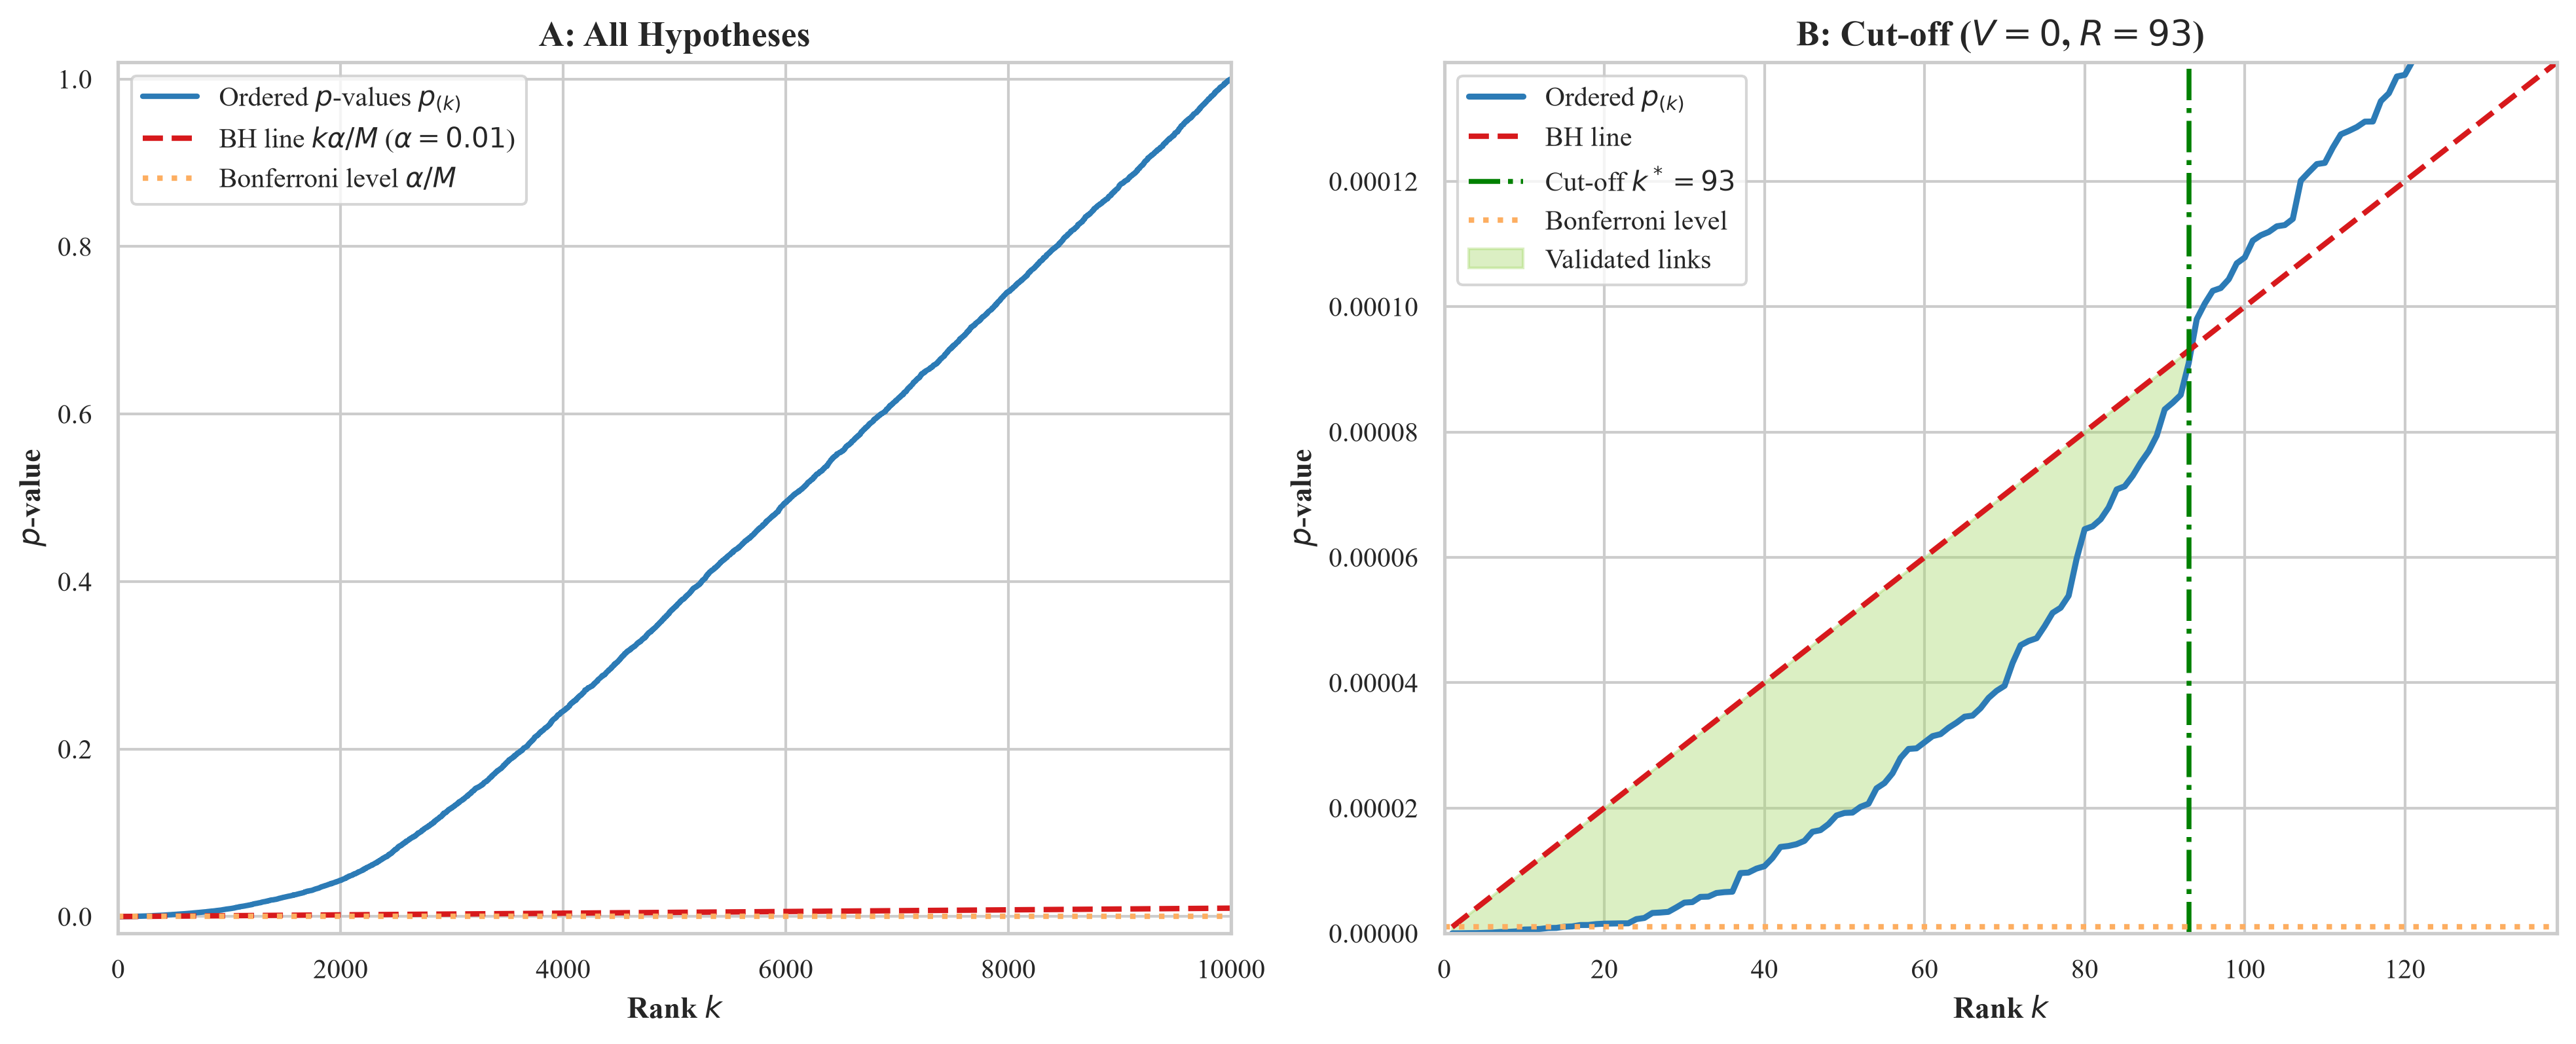

In [10]:
fig62, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.2), constrained_layout=True)

sorted_p = res_thm1["sorted_p"]
bh_line = res_thm1["bh_critical"]
k_star = res_thm1["k_star"]
n_tests = res_thm1["num_tests"]
alpha = res_thm1["nominal_fdr"]
rank = np.arange(1, n_tests + 1)

ax1.plot(rank, sorted_p, color="#2c7bb6", linewidth=2.0, label=r"Ordered $p$-values $p_{(k)}$")
ax1.plot(rank, bh_line, color="#d7191c", linestyle="--", linewidth=2.0, label=rf"BH line $k\alpha / M$ ($\alpha = {alpha}$)")
ax1.axhline(alpha / n_tests, color="#fdae61", linestyle=":", linewidth=2.0, label=r"Bonferroni level $\alpha / M$")
ax1.set_title("A: All Hypotheses")
ax1.set_xlabel(r"Rank $k$")
ax1.set_ylabel(r"$p$-value")
ax1.set_xlim(0, n_tests)
ax1.set_ylim(-0.02, 1.02)
ax1.legend(loc="upper left", frameon=True)

zoom = int(k_star * 1.5)
ax2.plot(rank[:zoom], sorted_p[:zoom], color="#2c7bb6", linewidth=2.2, label=r"Ordered $p_{(k)}$")
ax2.plot(rank[:zoom], bh_line[:zoom], color="#d7191c", linestyle="--", linewidth=2.0, label="BH line")
ax2.axvline(k_star, color="green", linestyle="-.", linewidth=1.8, label=rf"Cut-off $k^* = {k_star}$")
ax2.axhline(alpha / n_tests, color="#fdae61", linestyle=":", linewidth=2.0, label="Bonferroni level")
ax2.fill_between(rank[:k_star], sorted_p[:k_star], bh_line[:k_star], color="#a6d96a", alpha=0.4, label="Validated links")
ax2.set_title(rf"B: Cut-off ($V = {res_thm1['false_discoveries']}$, $R = {k_star}$)")
ax2.set_xlabel(r"Rank $k$")
ax2.set_ylabel(r"$p$-value")
ax2.set_xlim(0, zoom)
ax2.set_ylim(0, bh_line[zoom - 1])
ax2.legend(loc="upper left", frameon=True)

plt.show()

**Figure 6.2.** Sorted $p$-values with the Benjamini–Hochberg line and the Bonferroni level for a simulated mixture of true nulls and signals; panel B enlarges the cut-off.

*Source:* author's simulation based on Tumminello et al. (2011) and Saracco et al. (2017).

### 6.3 Exact Poisson-Binomial Distribution

**Question.** Does the discrete Fourier transform of the characteristic function give the exact distribution of the number of shared schools, and how far is the Poisson approximation?

**Check.** The probability mass function from the transform is compared with the successive convolution of the Bernoulli distributions, which is exact. The $\ell_1$ distance to the Poisson distribution is compared with Le Cam's bound $2\sum_i \pi_i^2$ (Saracco et al., 2017).

In [11]:
from scipy.stats import poisson


class PoissonBinomial:
    """Poisson-binomial distribution evaluated by the DFT of its characteristic function.

    Hong's algorithm as used by Saracco et al. (2017) for the exact p-values of shared neighbours.
    """

    def __init__(self, probabilities: np.ndarray) -> None:
        p = np.asarray(probabilities, dtype=np.float64)
        self.p = p[p > 0.0]
        self.n = len(self.p)

    def pmf(self) -> np.ndarray:
        """Probability mass function on 0..n."""
        if self.n == 0:
            return np.array([1.0])
        m = self.n + 1
        omega = 2.0 * np.pi / m
        phase = np.exp(-1j * omega * np.arange(m))
        characteristic = np.prod((1.0 - self.p[:, None]) + self.p[:, None] * phase[None, :], axis=0)
        return np.maximum(np.real(np.fft.ifft(characteristic)), 0.0)

    def sf(self, k: int) -> float:
        """Survival function P(X >= k)."""
        if k <= 0:
            return 1.0
        if k > self.n:
            return 0.0
        return float(np.sum(self.pmf()[k:]))

    def le_cam_bound(self) -> float:
        """Le Cam's bound 2 * sum(p_i^2) on the l1 distance to a Poisson distribution."""
        return float(2.0 * np.sum(self.p**2))

    def poisson_l1_distance(self) -> float:
        """l1 distance between the exact pmf and the Poisson pmf with the same mean."""
        lam = float(np.sum(self.p))
        support = np.arange(self.n + 1)
        inside = np.abs(self.pmf() - poisson.pmf(support, lam)).sum()
        return float(inside + poisson.sf(self.n, lam))


def pmf_by_convolution(probabilities: np.ndarray) -> np.ndarray:
    """Reference pmf by successive convolution of the Bernoulli distributions."""
    pmf = np.array([1.0])
    for p in probabilities:
        pmf = np.convolve(pmf, [1.0 - p, p])
    return pmf


pair_probabilities = np.array([0.02, 0.05, 0.12, 0.08, 0.15, 0.03, 0.01, 0.10, 0.04, 0.07])
pb = PoissonBinomial(pair_probabilities)
pmf_dft = pb.pmf()
pmf_ref = pmf_by_convolution(pair_probabilities)

max_abs_error = float(np.max(np.abs(pmf_dft - pmf_ref)))
l1_to_poisson = pb.poisson_l1_distance()
le_cam = pb.le_cam_bound()

assert max_abs_error < 1e-12, f"DFT-CF differs from the convolution: {max_abs_error}"
assert l1_to_poisson < le_cam, "Le Cam's inequality violated."

print(f"Bernoulli trials:                    {pb.n}")
print(f"Mean / variance:                     {pair_probabilities.sum():.4f} / {(pair_probabilities * (1 - pair_probabilities)).sum():.4f}")
print(f"Max |DFT-CF - convolution|:          {max_abs_error:.2e}")
print(f"l1 distance to Poisson:              {l1_to_poisson:.4f}")
print(f"Le Cam bound 2 * sum(p_i^2):         {le_cam:.4f}")
print(f"Exact P(X >= 3):                     {pb.sf(3):.6f}")

Bernoulli trials:                    10
Mean / variance:                     0.6700 / 0.6063
Max |DFT-CF - convolution|:          6.54e-17
l1 distance to Poisson:              0.0501
Le Cam bound 2 * sum(p_i^2):         0.1274
Exact P(X >= 3):                     0.022912


### 6.4 Noise-Corrected Backbone

**Question.** Does the noise-corrected filter keep a group of suppliers with unusually many shared schools and drop the links that the strength of a hub explains?

**Why a comparison with the disparity filter.** The disparity filter looks at one end node of a link, so a hub tends to keep its links. The noise-corrected filter compares each link with the value expected from the strengths of both end nodes (Coscia and Neffke, 2017).

**How to read.** In panel A each point is a link. The dashed line is the cut-off $\delta = 2.32$, and red points are the links that the noise-corrected filter keeps. Panel B shows how many links of each weight the two filters keep.

**What the figure is not.** It is a simulation of co-occurrence counts with a hub and a planted group, not the supplier network of the programme.

In [12]:
def noise_corrected_backbone(weights: np.ndarray, delta: float = 2.32) -> dict[str, np.ndarray]:
    """Noise-corrected backbone of a weighted network (Coscia and Neffke, 2017).

    A link is kept if the transformed lift exceeds delta standard deviations;
    delta = 2.32 corresponds to p of about 0.01.
    """
    w = np.array(weights, dtype=np.float64)
    np.fill_diagonal(w, 0.0)
    n_out = w.sum(axis=1)
    n_in = w.sum(axis=0)
    n_tot = w.sum()
    if n_tot <= 0:
        raise ValueError("The weight matrix has no links.")

    with np.errstate(divide="ignore", invalid="ignore"):
        prod = np.outer(n_out, n_in)
        kappa = n_tot / prod
        lift = (kappa * w - 1.0) / (kappa * w + 1.0)
        d_kappa = 1.0 / prod - n_tot * (n_out[:, None] + n_in[None, :]) / prod**2

        # Beta prior fitted to the hypergeometric moments, posterior mean of P_ij
        mu = prod / n_tot**2
        var_prior = prod * (n_tot - n_out)[:, None] * (n_tot - n_in)[None, :] / (n_tot**4 * (n_tot - 1.0))
        a = mu**2 / var_prior * (1.0 - mu) - mu
        b = mu * ((1.0 - mu) ** 2 / var_prior + 1.0) - 1.0
        p_post = (w + a) / (n_tot + a + b)

        var_n = n_tot * p_post * (1.0 - p_post)
        var_lift = var_n * (2.0 * (kappa + w * d_kappa) / (kappa * w + 1.0) ** 2) ** 2
        score = lift / np.sqrt(var_lift)

    score[~np.isfinite(score)] = 0.0
    lift[~np.isfinite(lift)] = -1.0
    return {"score": score, "lift": lift, "backbone": (score > delta) & (w > 0)}


def disparity_filter(weights: np.ndarray, alpha: float = 0.05) -> np.ndarray:
    """Disparity filter, the unilateral baseline described by Coscia and Neffke (2017)."""
    w = np.array(weights, dtype=np.float64)
    np.fill_diagonal(w, 0.0)
    degree = np.sum(w > 0, axis=1)
    strength = w.sum(axis=1)
    with np.errstate(divide="ignore", invalid="ignore"):
        share = w / strength[:, None]
        p_value = (1.0 - share) ** np.maximum(degree[:, None] - 1.0, 0.0)
    p_value[np.isnan(p_value)] = 1.0
    return (np.minimum(p_value, p_value.T) < alpha) & (w > 0)


# Synthetic co-occurrence counts: activity-driven ties, a hub (node 0) and a tightly connected group (nodes 10-14)
rng = np.random.default_rng(ModelConfig.SEED)
n_nodes = 80
activity = rng.lognormal(mean=0.0, sigma=0.8, size=n_nodes)
activity[0] *= 8.0
group_nodes = list(range(10, 15))
expected_counts = 0.8 * np.outer(activity, activity)
expected_counts[np.ix_(group_nodes, group_nodes)] += 12.0
upper_counts = np.triu(rng.poisson(expected_counts), k=1)
w_synth = (upper_counts + upper_counts.T).astype(np.float64)

nc_res = noise_corrected_backbone(w_synth)
df_mask = disparity_filter(w_synth)

hub_links = np.zeros_like(df_mask)
hub_links[0, 1:] = True
hub_links[1:, 0] = True
group_links = np.zeros_like(df_mask)
group_links[np.ix_(group_nodes, group_nodes)] = True
np.fill_diagonal(group_links, False)

print(f"Links in the network:                    {int(np.sum(w_synth > 0) / 2)}")
print(f"Links kept by the disparity filter:      {int(np.sum(df_mask) / 2)}")
print(f"Links kept by the noise-corrected filter: {int(np.sum(nc_res['backbone']) / 2)}")
print(f"Hub links kept (disparity / NC):         {int(np.sum(df_mask & hub_links) / 2)} / {int(np.sum(nc_res['backbone'] & hub_links) / 2)} of {int(np.sum(hub_links) / 2)}")
print(f"Group links kept (disparity / NC):       {int(np.sum(df_mask & group_links) / 2)} / {int(np.sum(nc_res['backbone'] & group_links) / 2)} of {int(np.sum(group_links) / 2)}")

Links in the network:                    1822
Links kept by the disparity filter:      108
Links kept by the noise-corrected filter: 245
Hub links kept (disparity / NC):         61 / 6 of 79
Group links kept (disparity / NC):       10 / 10 of 10


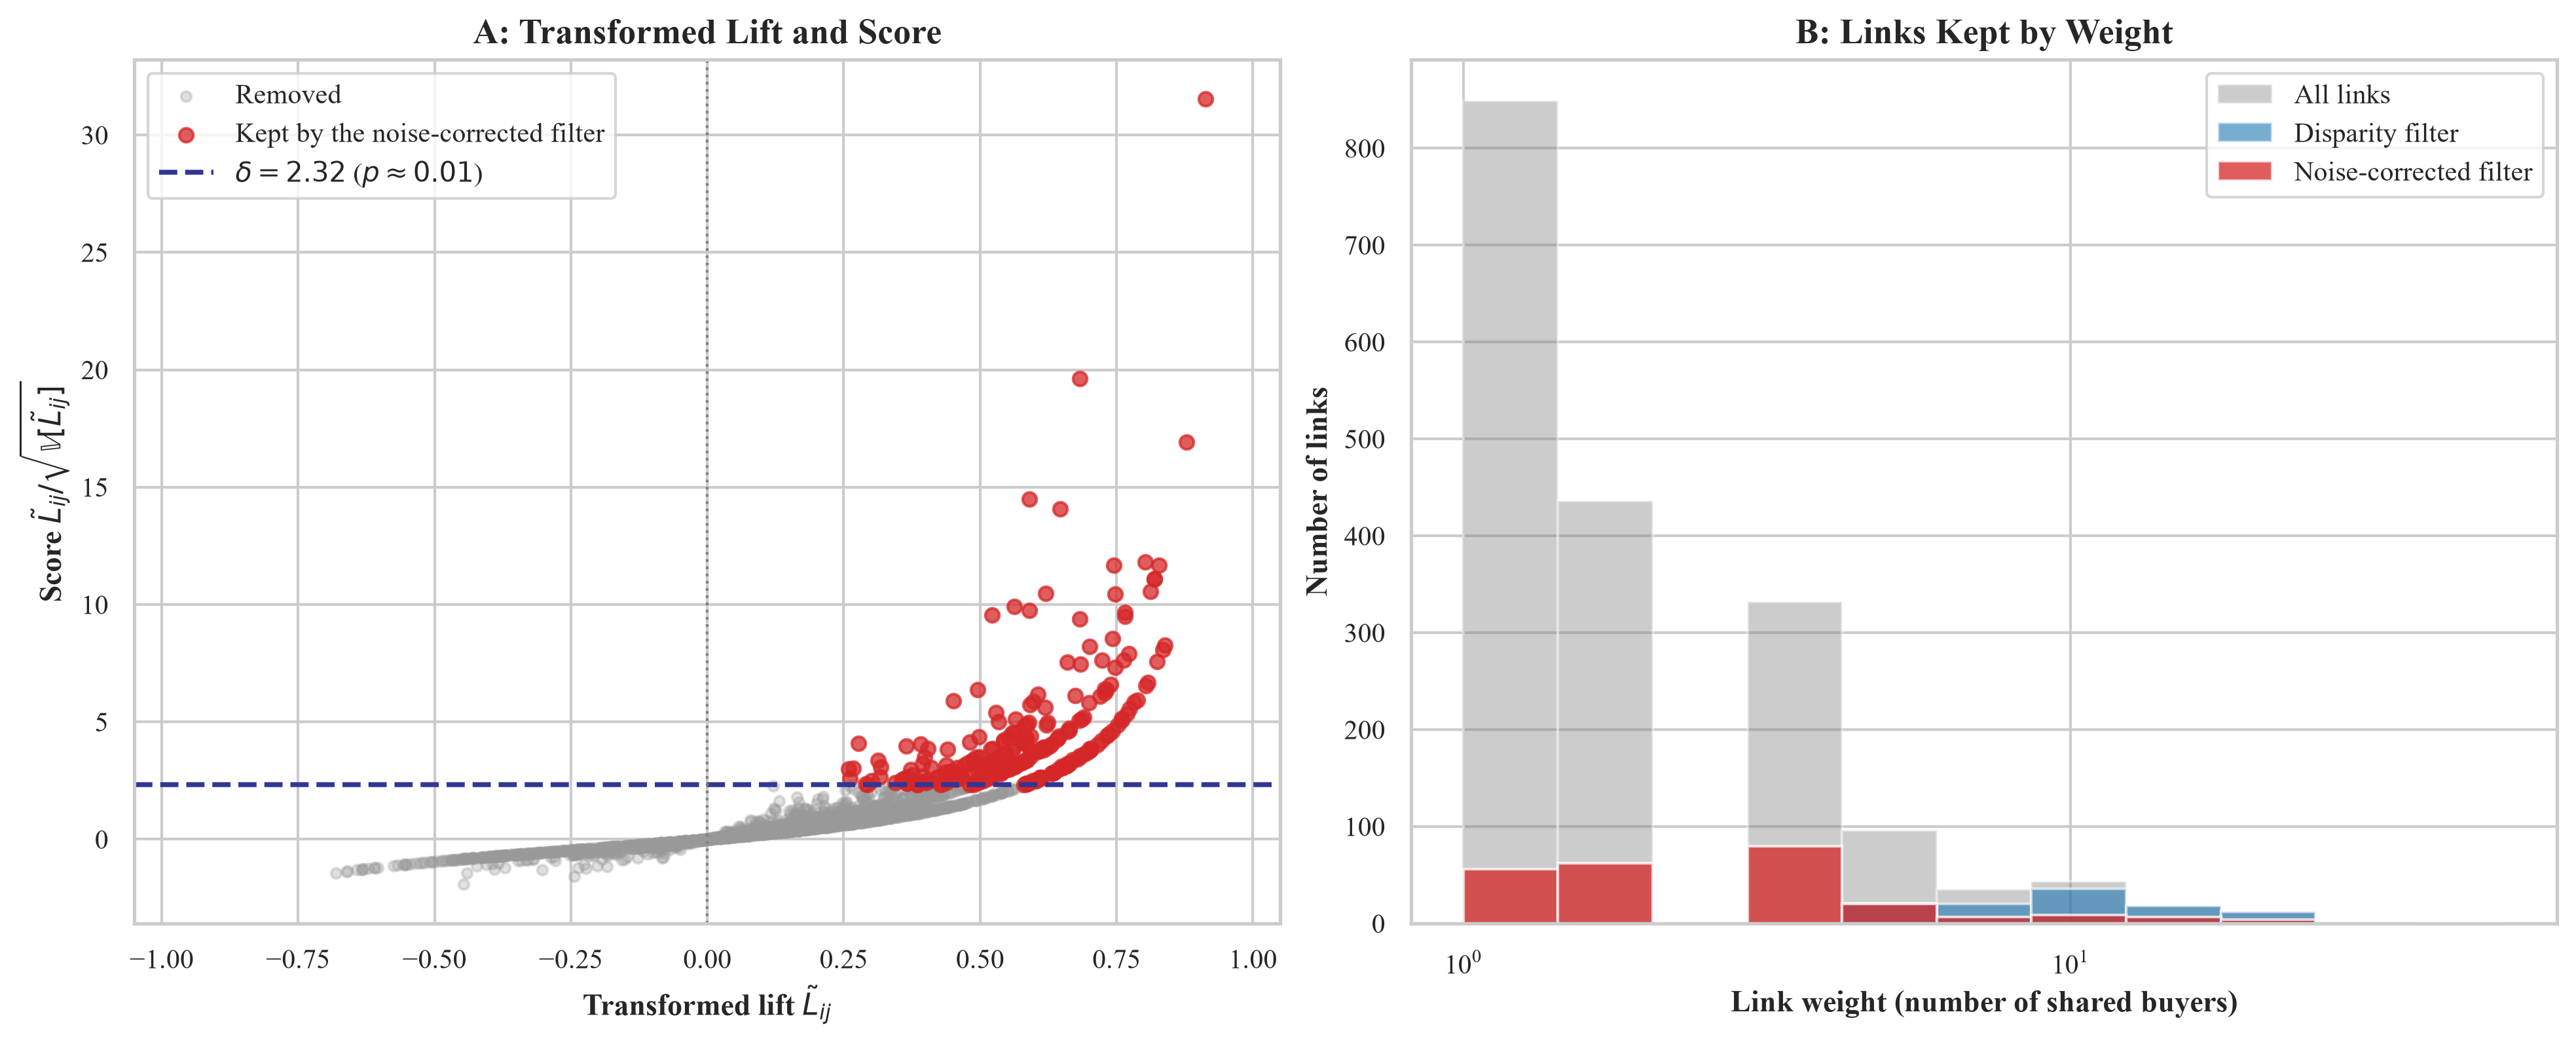

In [13]:
fig63, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.2), constrained_layout=True)

upper = np.triu(np.ones_like(w_synth, dtype=bool), k=1)
present = upper & (w_synth > 0)
weights_upper = w_synth[present]
score_upper = nc_res["score"][present]
lift_upper = nc_res["lift"][present]
nc_kept = nc_res["backbone"][present]
df_kept = df_mask[present]

ax1.scatter(lift_upper[~nc_kept], score_upper[~nc_kept], color="#999999", alpha=0.3, s=14, label="Removed")
ax1.scatter(lift_upper[nc_kept], score_upper[nc_kept], color="#d62728", alpha=0.75, s=26, label="Kept by the noise-corrected filter")
ax1.axhline(2.32, color="#313695", linestyle="--", linewidth=1.8, label=r"$\delta = 2.32$ ($p \approx 0.01$)")
ax1.axvline(0.0, color="gray", linestyle=":", linewidth=1.0)
ax1.set_title(r"A: Transformed Lift and Score")
ax1.set_xlabel(r"Transformed lift $\tilde{L}_{ij}$")
ax1.set_ylabel(r"Score $\tilde{L}_{ij} / \sqrt{\mathbb{V}[\tilde{L}_{ij}]}$")
ax1.set_xlim(-1.05, 1.05)
ax1.legend(loc="upper left", frameon=True)

bins = np.logspace(0.0, np.log10(weights_upper.max()), 12)
ax2.hist(weights_upper, bins=bins, alpha=0.4, color="gray", label="All links")
ax2.hist(weights_upper[df_kept], bins=bins, alpha=0.6, color="#1f77b4", label="Disparity filter")
ax2.hist(weights_upper[nc_kept], bins=bins, alpha=0.75, color="#d62728", label="Noise-corrected filter")
ax2.set_xscale("log")
ax2.set_title("B: Links Kept by Weight")
ax2.set_xlabel("Link weight (number of shared buyers)")
ax2.set_ylabel("Number of links")
ax2.legend(loc="upper right", frameon=True)

plt.show()

**Figure 6.3.** Transformed lift and score of the links of a simulated network (panel A) and the links kept by the disparity filter and by the noise-corrected filter by weight (panel B).

*Source:* author's simulation based on Coscia and Neffke (2017).

### 6.5 Coherence and Exclusivity of Groups

**Question.** Do the two group metrics separate a tight group with weak ties to the rest of the market from ordinary groups and from a hub with spokes?

**Why a plane of two metrics.** Coherence measures how uniform the ties inside a group are, and exclusivity measures how closed the group is towards the rest of the market (Wachs and Kertész, 2019). A single metric does not separate the three types of group.

**How to read.** Each blue point is a random group of ordinary participants. The star is the tight group, the square an ordinary group and the triangle a hub with three spokes. The shaded zone is an illustrative screening zone. Its cut-offs are chosen for this figure and are not taken from the source.

**What the figure is not.** It is a simulated market of 60 participants, and a position in the shaded zone is not evidence of collusion.

In [14]:
def group_coherence_exclusivity(weights: np.ndarray, group: list[int]) -> tuple[float, float]:
    """Coherence C_G and exclusivity E_G of a group of nodes (Wachs and Kertész, 2019)."""
    w = np.asarray(weights, dtype=np.float64)
    nodes = sorted(set(group))
    if len(nodes) < 2:
        return 0.0, 0.0

    internal = w[np.ix_(nodes, nodes)][np.triu_indices(len(nodes), k=1)]
    active = internal[internal > 0]
    if active.size == 0:
        return 0.0, 0.0

    coherence = float(np.exp(np.mean(np.log(active))) / np.mean(active))
    outside = np.setdiff1d(np.arange(w.shape[0]), nodes)
    s_in = float(internal.sum())
    s_out = float(w[np.ix_(nodes, outside)].sum())
    return coherence, s_in / (s_in + s_out)


n_market = 60
rng = np.random.default_rng(ModelConfig.SEED)
w_market = np.triu(rng.exponential(scale=2.5, size=(n_market, n_market)), k=1)
w_market = w_market + w_market.T

# Group A: strong, uniform ties inside the group and weak ties to the rest of the market
tight_nodes = [0, 1, 2]
w_market[np.ix_(tight_nodes, tight_nodes)] = 120.0
np.fill_diagonal(w_market, 0.0)
w_market[tight_nodes, 3:] *= 0.02
w_market[3:, tight_nodes] *= 0.02

# Group B: ordinary market participants (no special structure)
open_nodes = [10, 11, 12, 13]

# Group C: one supplier with strong ties to three others that are not tied to each other
hub_nodes = [20, 21, 22, 23]
for spoke in hub_nodes[1:]:
    w_market[20, spoke] = w_market[spoke, 20] = 60.0

c_tight, e_tight = group_coherence_exclusivity(w_market, tight_nodes)
c_open, e_open = group_coherence_exclusivity(w_market, open_nodes)
c_hub, e_hub = group_coherence_exclusivity(w_market, hub_nodes)

print(f"Tight group:   coherence {c_tight:.3f} | exclusivity {e_tight:.3f}")
print(f"Open market:   coherence {c_open:.3f} | exclusivity {e_open:.3f}")
print(f"Hub and spokes: coherence {c_hub:.3f} | exclusivity {e_hub:.3f}")

Tight group:   coherence 1.000 | exclusivity 0.979
Open market:   coherence 0.794 | exclusivity 0.015
Hub and spokes: coherence 0.233 | exclusivity 0.255


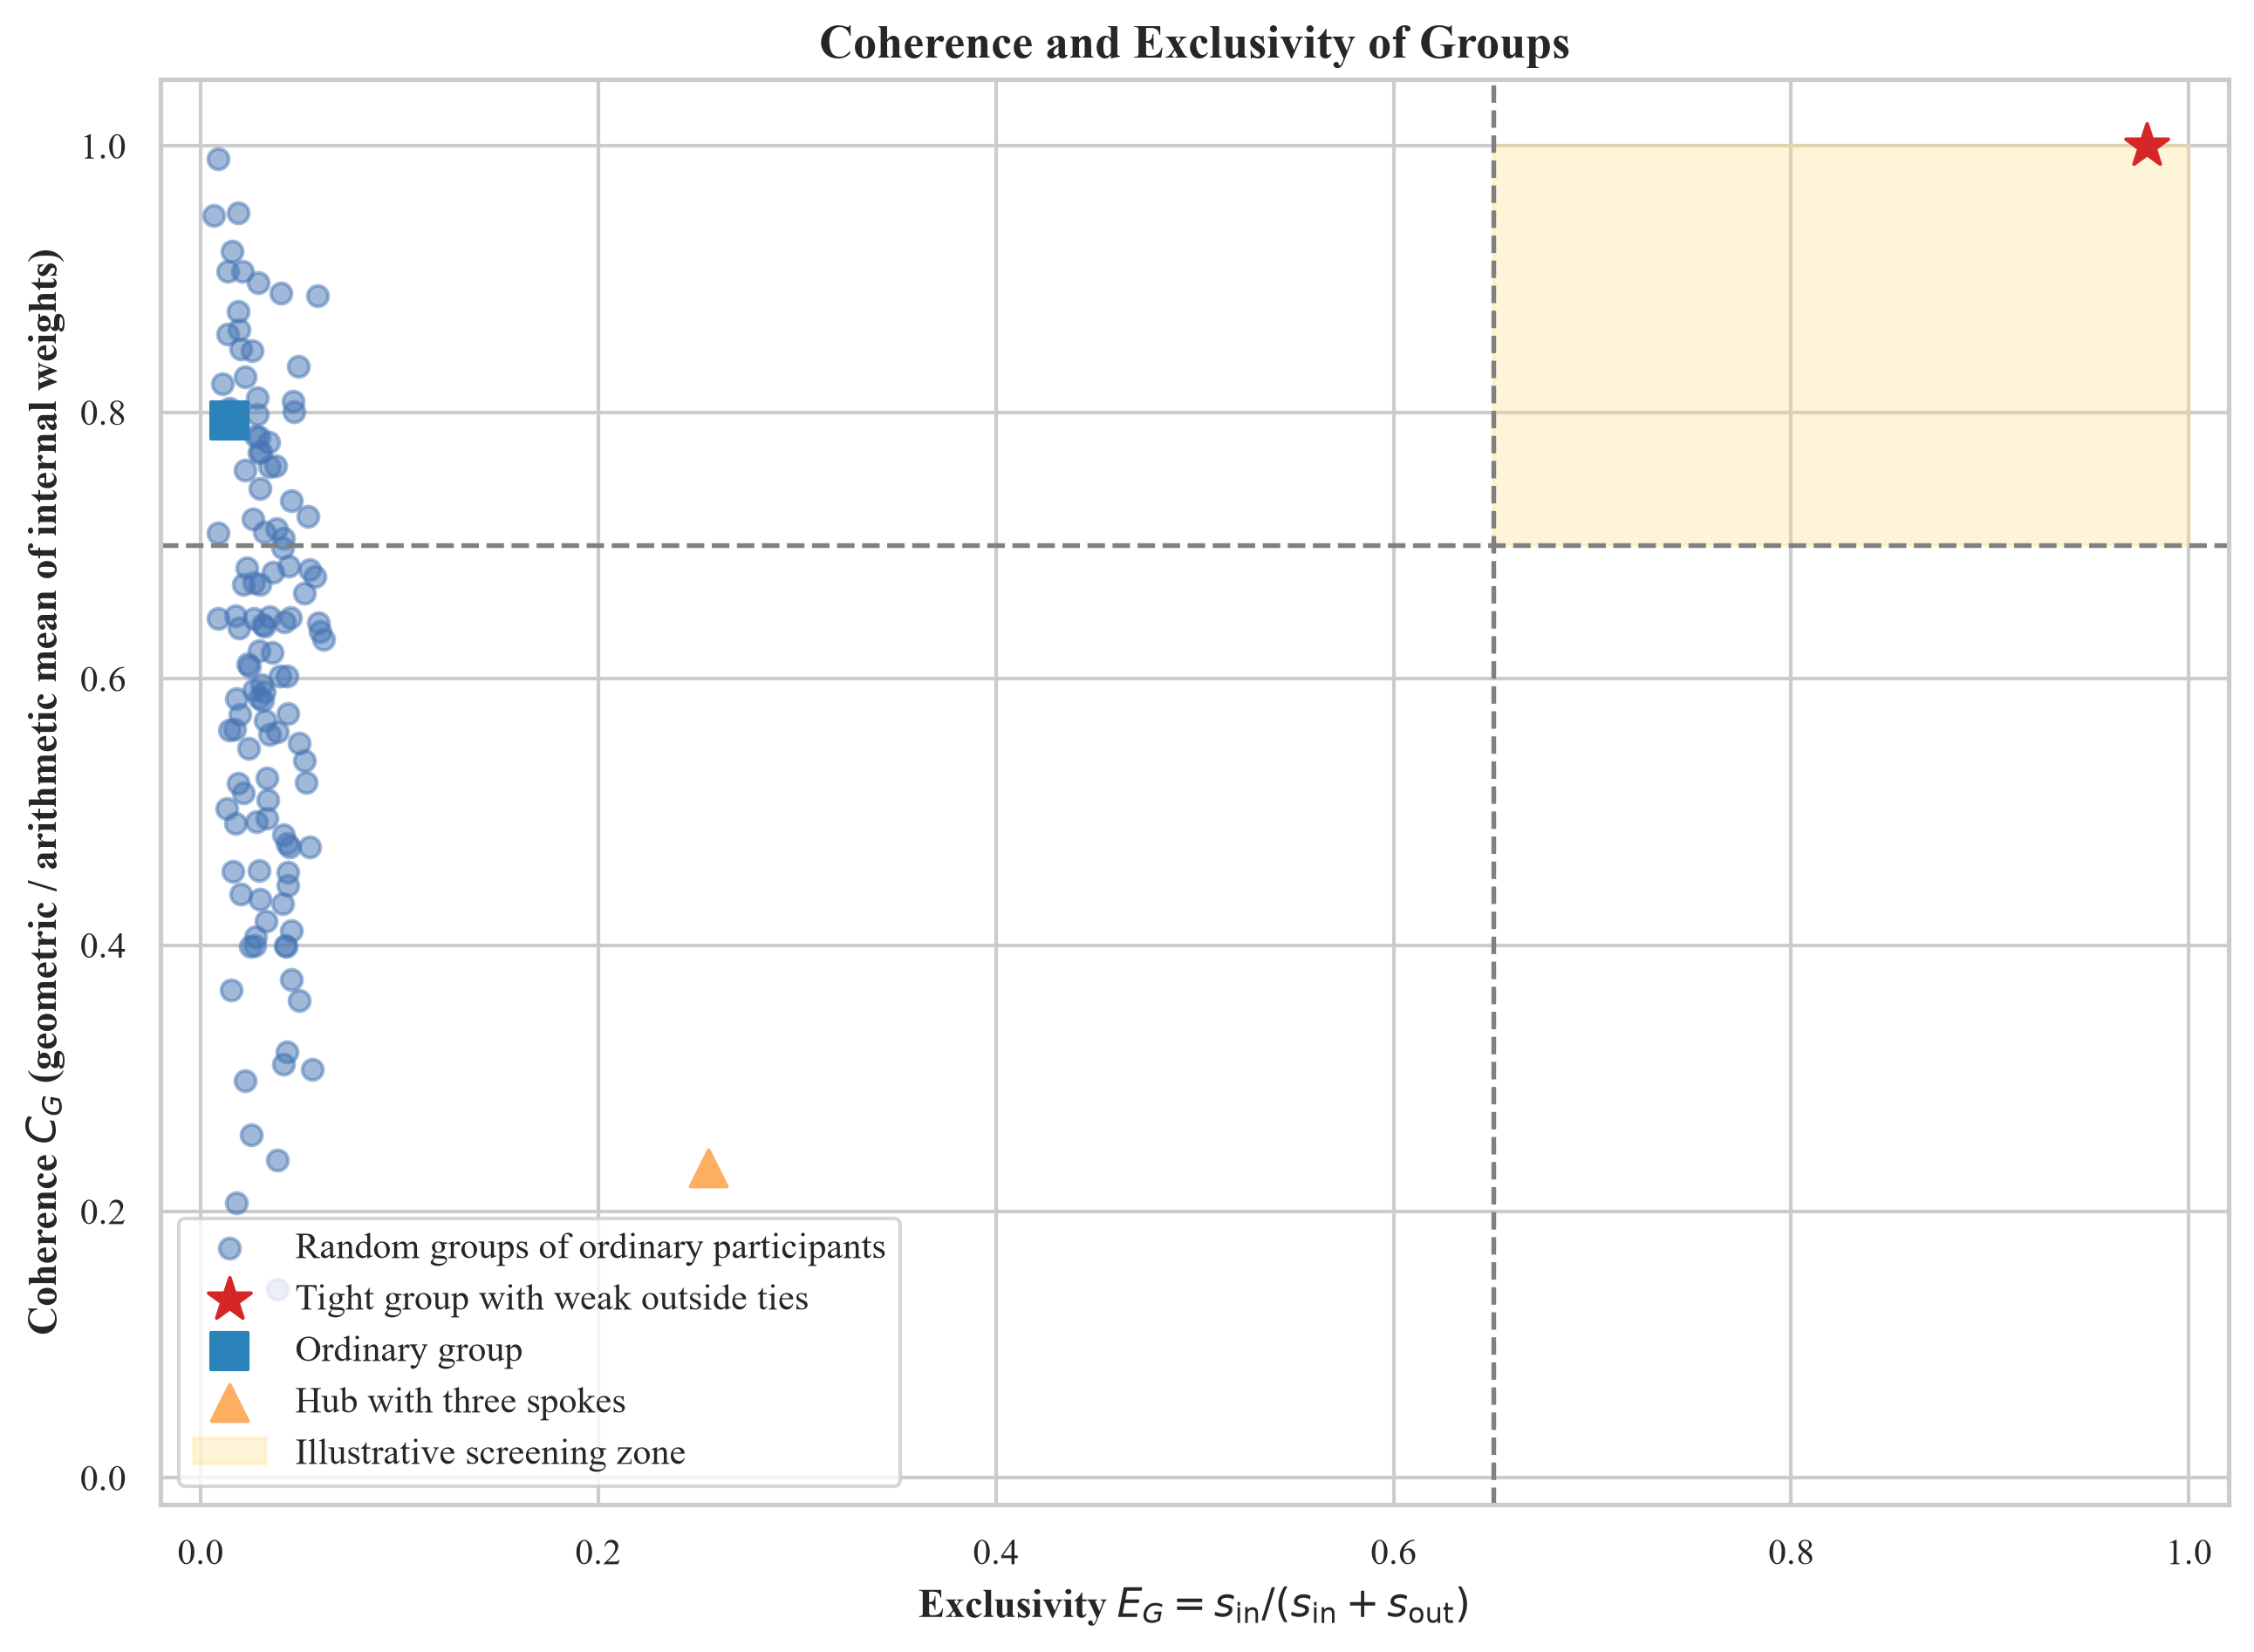

In [15]:
fig64, ax = plt.subplots(figsize=(8.5, 6.2), constrained_layout=True)

rng = np.random.default_rng(ModelConfig.SEED)
pool = np.setdiff1d(np.arange(n_market), tight_nodes + hub_nodes)
random_groups = [group_coherence_exclusivity(w_market, list(rng.choice(pool, size=rng.integers(3, 7), replace=False)))
                 for _ in range(120)]
coh_random, exc_random = zip(*random_groups)

ax.scatter(exc_random, coh_random, color="#4575b4", alpha=0.5, s=32, label="Random groups of ordinary participants")
ax.scatter([e_tight], [c_tight], color="#d62728", s=150, marker="*", zorder=5, label="Tight group with weak outside ties")
ax.scatter([e_open], [c_open], color="#2b83ba", s=100, marker="s", zorder=5, label="Ordinary group")
ax.scatter([e_hub], [c_hub], color="#fdae61", s=100, marker="^", zorder=5, label="Hub with three spokes")
ax.axvline(0.65, color="gray", linestyle="--", linewidth=1.3)
ax.axhline(0.70, color="gray", linestyle="--", linewidth=1.3)
ax.fill_between([0.65, 1.0], 0.70, 1.0, color="#fee090", alpha=0.35, label="Illustrative screening zone")

ax.set_title(r"Coherence and Exclusivity of Groups")
ax.set_xlabel(r"Exclusivity $E_G = s_{\mathrm{in}} / (s_{\mathrm{in}} + s_{\mathrm{out}})$")
ax.set_ylabel(r"Coherence $C_G$ (geometric / arithmetic mean of internal weights)")
ax.set_xlim(-0.02, 1.02)
ax.set_ylim(-0.02, 1.05)
ax.legend(loc="lower left", frameon=True)

plt.show()

**Figure 6.4.** Coherence $C_G$ and exclusivity $E_G$ of random groups and of three constructed groups in a simulated market.

*Source:* author's simulation based on Wachs and Kertész (2019).

### 6.6 Digits of the Spacings (Theorem 2)

**Question.** Do the spacings of smooth contract values follow the digit pattern of the exponential distribution, and do rounded values depart from it?

**Check.** The deviation of the exponential distribution from Benford's law is evaluated from the series in the proof of Theorem 2. Normalised spacings of 15,000 uniform values are compared with the same values rounded to BGN 10, with the Kolmogorov–Smirnov distance $D$ of the mantissa from the uniform distribution (Miller and Nigrini, 2006).

**How to read.** Panel A gives the first-digit frequencies of the spacings, panel B the distribution function of the mantissa. Smooth values follow the diagonal, and rounded values depart from it because their spacings repeat.

**What the figure is not.** It is a simulation. A departure of real contract values from the diagonal is a risk indicator that calls for an explanation, not proof of manipulation.

In [16]:
from scipy.stats import kstest


def exponential_digit_probabilities(base: float = 10.0, terms: int = 40) -> np.ndarray:
    """First-digit probabilities of a standard exponential variable.

    P(D1 = d) = sum_k [exp(-d * B^k) - exp(-(d + 1) * B^k)] (Miller and Nigrini, 2006).
    """
    k = np.arange(-terms, terms + 1)
    d = np.arange(1, int(base))
    return np.array([np.sum(np.exp(-x * base**k) - np.exp(-(x + 1) * base**k)) for x in d])


def exponential_mantissa_deviation(base: float = 10.0, terms: int = 40, grid: int = 20001) -> float:
    """Supremum of |F(b) - b| for log_B of a standard exponential variable modulo 1."""
    b = np.linspace(0.0, 1.0, grid)
    k = np.arange(-terms, terms + 1)[:, None]
    cdf = np.sum(np.exp(-base**k) - np.exp(-base ** (b[None, :] + k)), axis=0)
    return float(np.max(np.abs(cdf - b)))


def spacing_mantissas(values: np.ndarray, upper: float) -> tuple[np.ndarray, int]:
    """Mantissas log10(Z) mod 1 of the normalised spacings Z of ordered values on [0, upper]."""
    ordered = np.sort(values)
    z = np.diff(ordered) * len(values) / upper
    positive = z[z > 0]
    log_z = np.log10(positive)
    return log_z - np.floor(log_z), int(len(z) - len(positive))


rng = np.random.default_rng(ModelConfig.SEED)
n_values, upper_value = 15000, 100000.0
smooth = rng.uniform(0.0, upper_value, size=n_values)
rounded = np.round(smooth / 10.0) * 10.0

mant_smooth, zeros_smooth = spacing_mantissas(smooth, upper_value)
mant_rounded, zeros_rounded = spacing_mantissas(rounded, upper_value)

digits = np.arange(1, 10)
p_benford = np.log10(1.0 + 1.0 / digits)


def first_digit_frequencies(mantissas: np.ndarray) -> np.ndarray:
    return np.bincount(np.floor(10.0**mantissas).astype(int), minlength=10)[1:10] / len(mantissas)


p_smooth = first_digit_frequencies(mant_smooth)
p_rounded = first_digit_frequencies(mant_rounded)

digit_deviation = float(np.max(np.abs(exponential_digit_probabilities() - p_benford)))
cdf_deviation = exponential_mantissa_deviation()
d_smooth = float(kstest(mant_smooth, "uniform").statistic)
d_rounded = float(kstest(mant_rounded, "uniform").statistic)
sampling_band = 1.36 / np.sqrt(len(mant_smooth))

assert 0.0285 < digit_deviation < 0.030, f"Digit deviation of the exponential distribution outside 0.029-0.030: {digit_deviation:.5f}"
assert d_smooth <= cdf_deviation + sampling_band, "Smooth values deviate by more than the theoretical bound plus sampling error."
assert d_rounded > 3.0 * d_smooth, "Rounded values are not clearly separated from smooth values."

print(f"Exp(1), base 10: largest first-digit deviation from Benford {digit_deviation:.4f}, sup |F(b) - b| {cdf_deviation:.4f}")
print(f"Sampling band (95%) for n = {len(mant_smooth)}:          {sampling_band:.4f}")
print(f"Smooth values:  D = {d_smooth:.4f} | max digit deviation {np.max(np.abs(p_smooth - p_benford)):.4f} | zero spacings {zeros_smooth}")
print(f"Rounded values: D = {d_rounded:.4f} | max digit deviation {np.max(np.abs(p_rounded - p_benford)):.4f} | zero spacings {zeros_rounded}")

Exp(1), base 10: largest first-digit deviation from Benford 0.0286, sup |F(b) - b| 0.0305
Sampling band (95%) for n = 14999:          0.0111
Smooth values:  D = 0.0318 | max digit deviation 0.0249 | zero spacings 0
Rounded values: D = 0.5959 | max digit deviation 0.4709 | zero spacings 7264


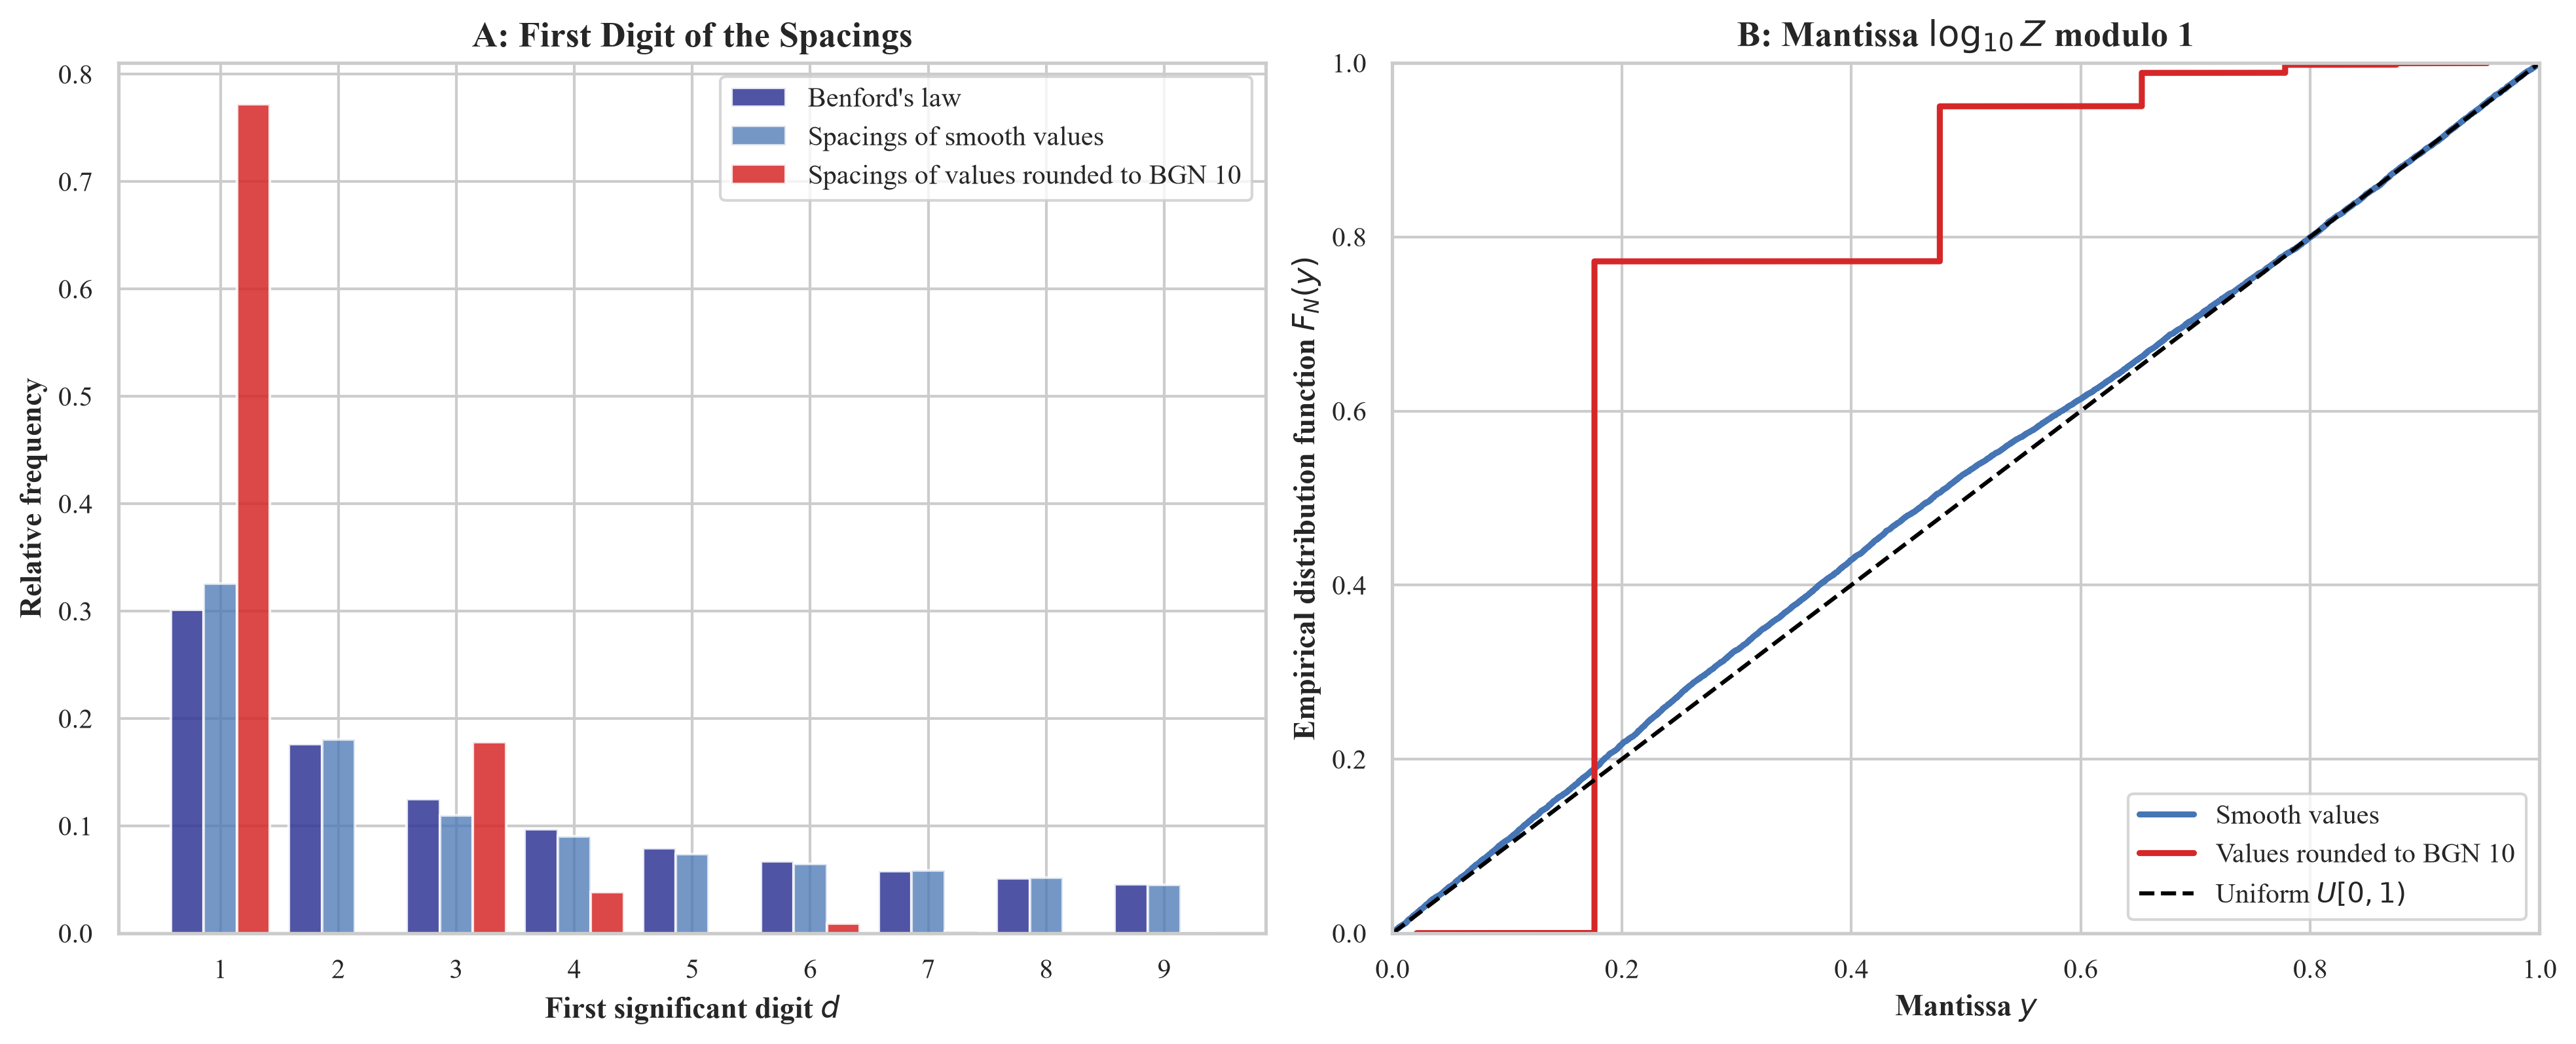

In [17]:
fig65, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.2), constrained_layout=True)

width = 0.28
ax1.bar(digits - width, p_benford, width=width, color="#313695", alpha=0.85, label="Benford's law")
ax1.bar(digits, p_smooth, width=width, color="#4575b4", alpha=0.75, label="Spacings of smooth values")
ax1.bar(digits + width, p_rounded, width=width, color="#d62728", alpha=0.85, label="Spacings of values rounded to BGN 10")
ax1.set_title("A: First Digit of the Spacings")
ax1.set_xlabel(r"First significant digit $d$")
ax1.set_ylabel("Relative frequency")
ax1.set_xticks(digits)
ax1.legend(loc="upper right", frameon=True)

for mantissas, color, label in [(mant_smooth, "#4575b4", "Smooth values"), (mant_rounded, "#d62728", "Values rounded to BGN 10")]:
    ordered = np.sort(mantissas)
    ax2.plot(ordered, np.arange(1, len(ordered) + 1) / len(ordered), color=color, linewidth=2.2, label=label)
ax2.plot([0, 1], [0, 1], color="black", linestyle="--", linewidth=1.5, label=r"Uniform $U[0, 1)$")
ax2.set_title(r"B: Mantissa $\log_{10} Z$ modulo 1")
ax2.set_xlabel(r"Mantissa $y$")
ax2.set_ylabel(r"Empirical distribution function $F_N(y)$")
ax2.set_xlim(0, 1)
ax2.set_ylim(0, 1)
ax2.legend(loc="lower right", frameon=True)

plt.show()

**Figure 6.5.** First-digit frequencies (panel A) and mantissa distribution (panel B) of the normalised spacings of simulated smooth values and of the same values rounded to BGN 10.

*Source:* author's simulation based on Miller and Nigrini (2006).

### 6.7 Recovery of a Known Bunching (Proposition 2)

**Question.** Does the polynomial counterfactual recover the number of contracts that were moved below a threshold?

**Check.** Contract values are drawn from a smooth log-normal distribution. Of the contracts between 50,000 and 53,000 BGN, 70% are moved to the interval just below 50,000 BGN. The estimated excess mass below and missing mass above the threshold are compared with the known number of moved contracts (Palguta and Pertold, 2017; Szűcs, 2024).

**How to read.** The red line is the counterfactual fitted to the bins outside the window of 3,000 BGN around the threshold. The orange area is the excess mass and the yellow area the missing mass.

**What the figure is not.** It is a simulation with a known shift, not an estimate from the contract data. The estimator with the Poisson regression of Section 5.3 is applied to the data in a later step.

In [18]:
def bunching_estimator(
    contract_values: np.ndarray,
    threshold: float,
    bin_width: float = 1000.0,
    window: tuple[float, float] = (20000.0, 80000.0),
    delta_below: float = 3000.0,
    delta_above: float = 3000.0,
    degree: int = 4,
) -> dict[str, float | np.ndarray]:
    """Excess and missing mass around a threshold with a polynomial counterfactual.

    The polynomial is fitted to the log counts of the bins outside the manipulation window
    (Palguta and Pertold, 2017; Szűcs, 2024).
    """
    values = contract_values[(contract_values >= window[0]) & (contract_values <= window[1])]
    edges = np.arange(window[0], window[1] + bin_width, bin_width)
    counts, edges = np.histogram(values, bins=edges)
    centers = (edges[:-1] + edges[1:]) / 2.0

    excluded = (centers >= threshold - delta_below) & (centers <= threshold + delta_above)
    z = (centers - threshold) / 10000.0
    coefficients = np.polyfit(z[~excluded], np.log(np.maximum(counts[~excluded], 1.0)), deg=degree)
    counterfactual = np.exp(np.polyval(coefficients, z))

    below = (centers >= threshold - delta_below) & (centers < threshold)
    above = (centers >= threshold) & (centers <= threshold + delta_above)
    excess = float(np.sum(counts[below] - counterfactual[below]))
    missing = float(np.sum(counterfactual[above] - counts[above]))
    height = float(np.exp(np.polyval(coefficients, 0.0)))

    return {
        "centers": centers,
        "observed": counts,
        "counterfactual": counterfactual,
        "threshold": threshold,
        "delta_below": delta_below,
        "delta_above": delta_above,
        "excess_mass": excess,
        "missing_mass": missing,
        "normalized_excess": excess / height,
    }


# Simulated contract values with a known number of contracts moved below the threshold
rng = np.random.default_rng(ModelConfig.SEED)
contracts = rng.lognormal(mean=10.6, sigma=0.55, size=12000)
candidates = np.flatnonzero((contracts >= 50000.0) & (contracts <= 53000.0))
moved = rng.choice(candidates, size=int(len(candidates) * 0.70), replace=False)
contracts[moved] = rng.uniform(48200.0, 49950.0, size=len(moved))

bunch_res = bunching_estimator(contracts, threshold=50000.0)
excess_error = abs(bunch_res["excess_mass"] - len(moved)) / len(moved)
missing_error = abs(bunch_res["missing_mass"] - len(moved)) / len(moved)

assert excess_error < 0.25, f"Excess mass {bunch_res['excess_mass']:.0f} differs from the {len(moved)} moved contracts."
assert missing_error < 0.25, f"Missing mass {bunch_res['missing_mass']:.0f} differs from the {len(moved)} moved contracts."

print(f"Threshold:                       {bunch_res['threshold']:,.0f} BGN excl. VAT")
print(f"Contracts moved below it:        {len(moved)}")
print(f"Estimated excess mass:           {bunch_res['excess_mass']:.1f} (relative error {excess_error:.1%})")
print(f"Estimated missing mass above:    {bunch_res['missing_mass']:.1f} (relative error {missing_error:.1%})")
print(f"Excess mass relative to h(T):    {bunch_res['normalized_excess']:.2f}")

Threshold:                       50,000 BGN excl. VAT
Contracts moved below it:        328
Estimated excess mass:           309.6 (relative error 5.6%)
Estimated missing mass above:    312.9 (relative error 4.6%)
Excess mass relative to h(T):    1.93


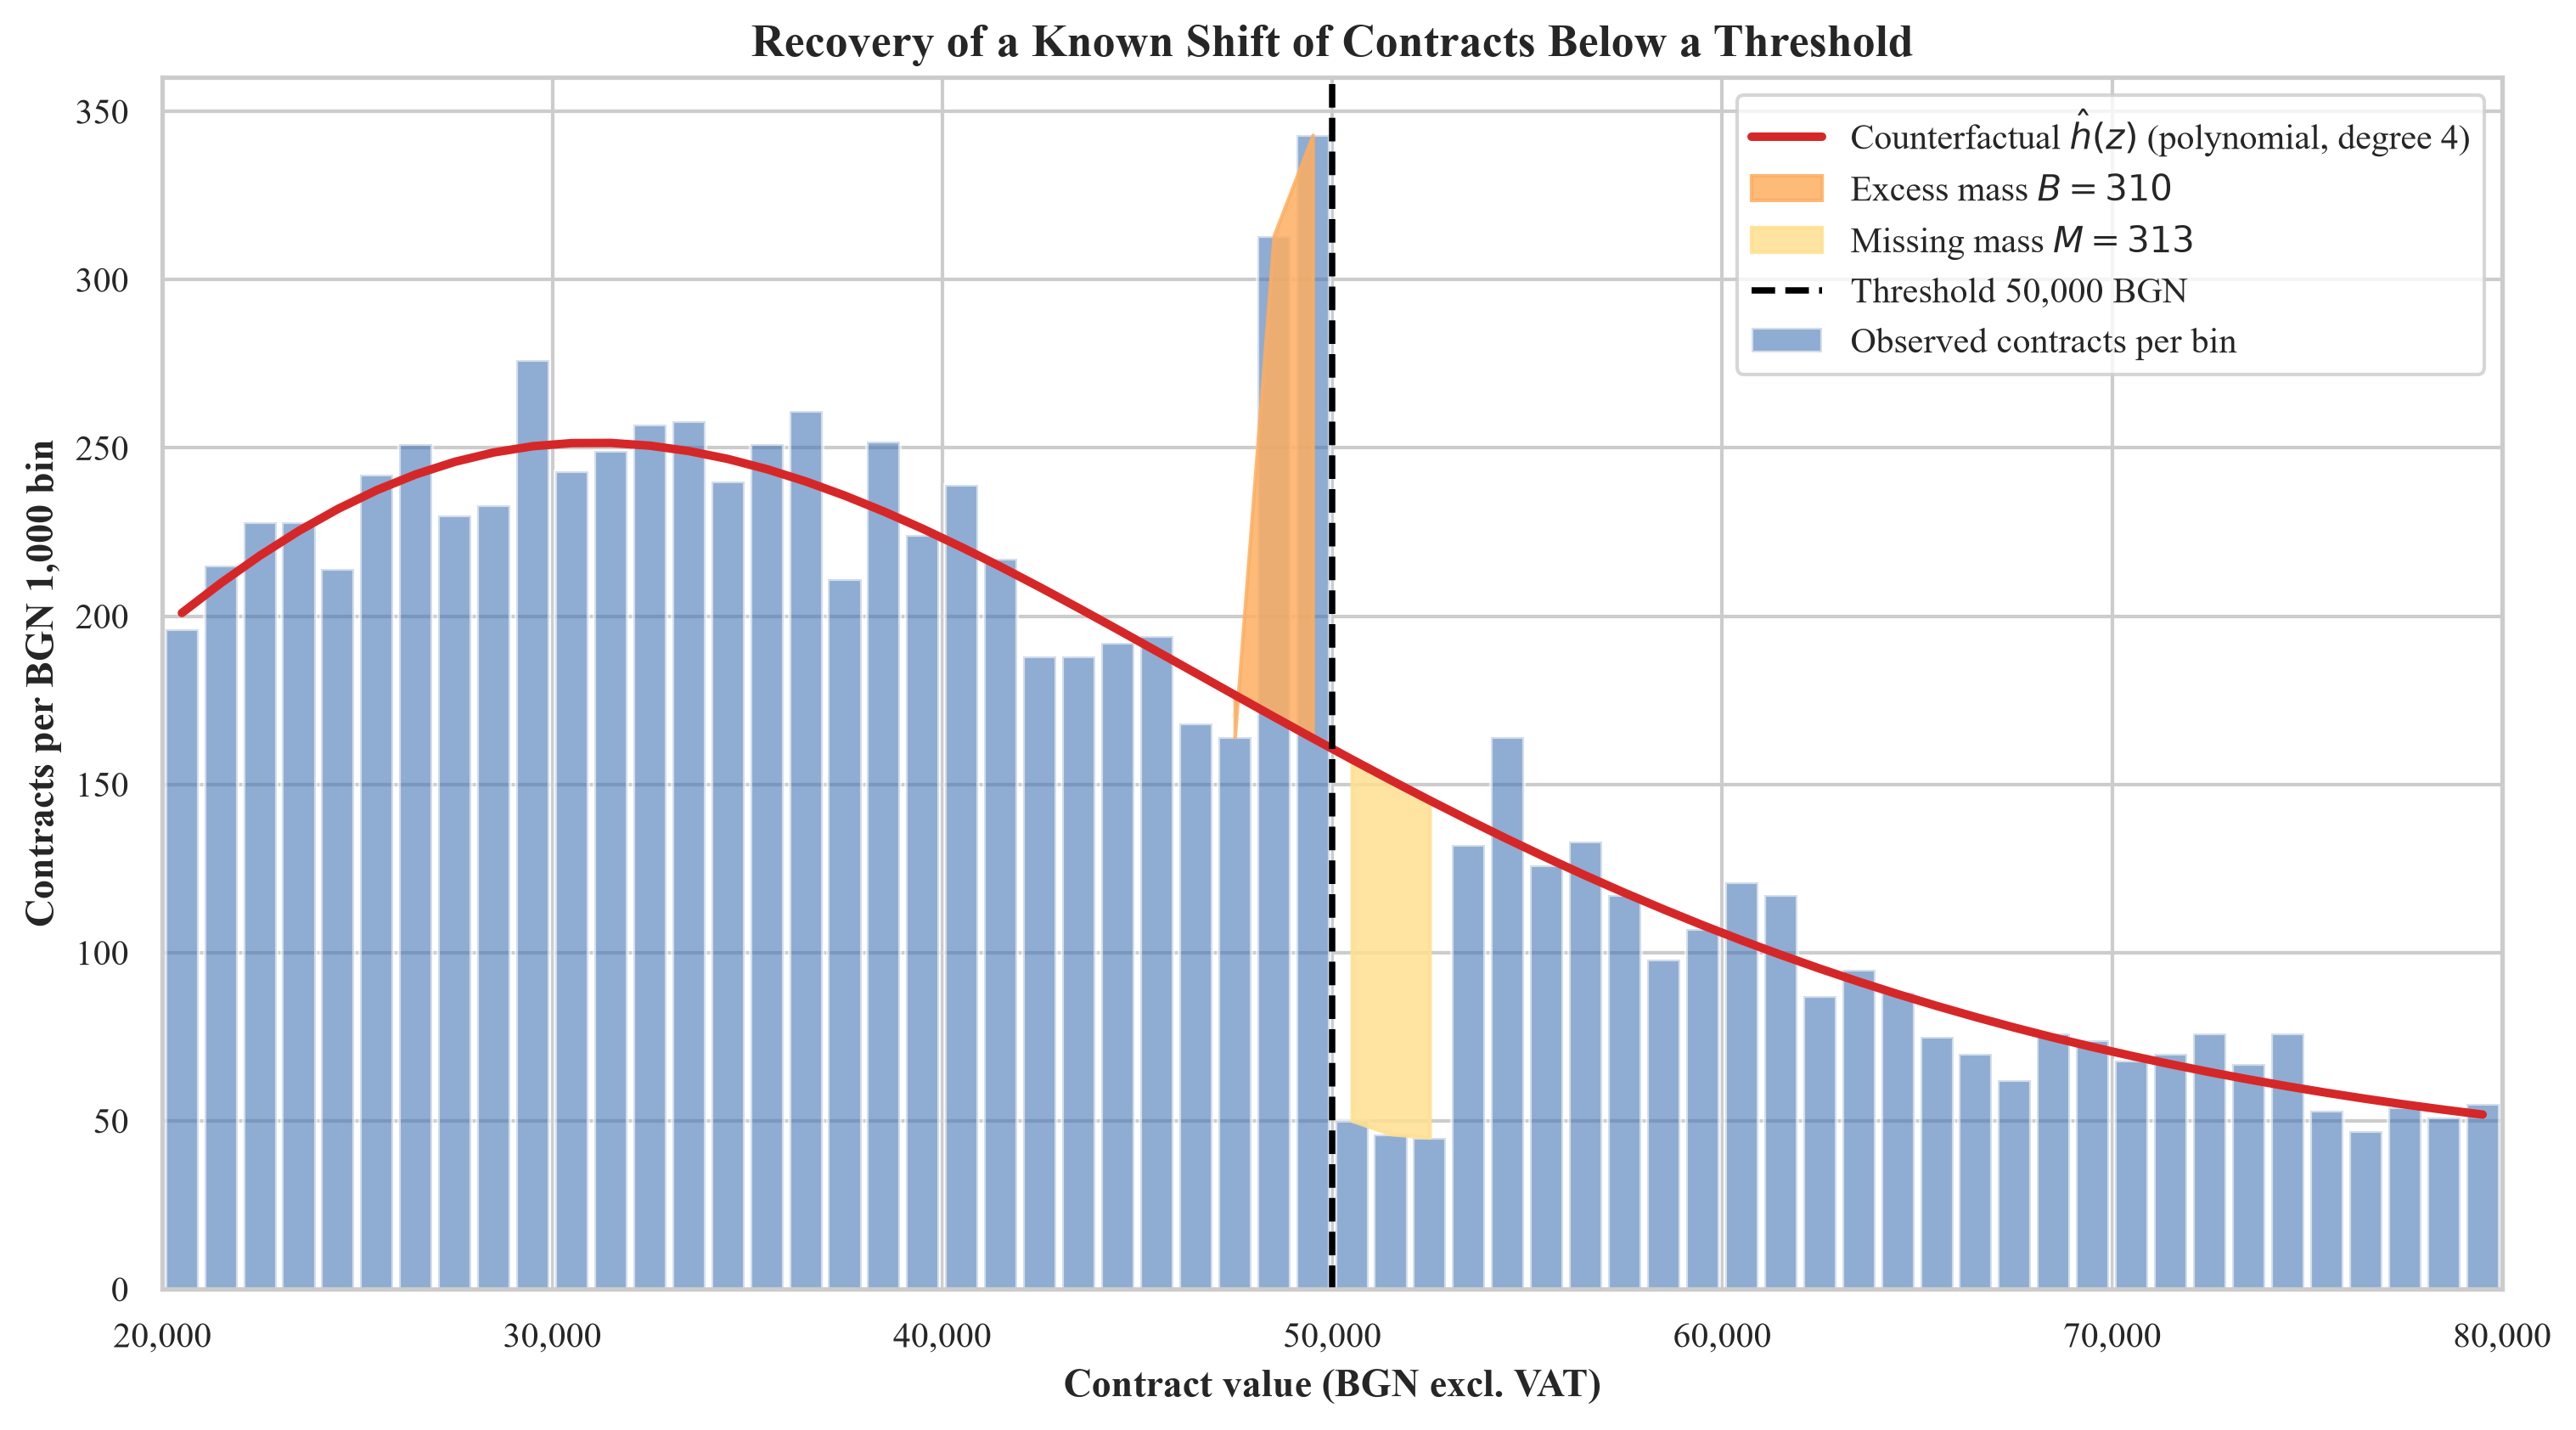

In [19]:
fig66, ax = plt.subplots(figsize=(10, 5.5), constrained_layout=True)

centers = bunch_res["centers"]
observed = bunch_res["observed"]
counterfactual = bunch_res["counterfactual"]
threshold = bunch_res["threshold"]

ax.bar(centers, observed, width=850.0, color="#4575b4", alpha=0.6, edgecolor="white", label="Observed contracts per bin")
ax.plot(centers, counterfactual, color="#d62728", linewidth=2.4, label=r"Counterfactual $\hat{h}(z)$ (polynomial, degree 4)")

below = (centers >= threshold - bunch_res["delta_below"]) & (centers < threshold)
ax.fill_between(centers[below], counterfactual[below], observed[below], color="#fdae61", alpha=0.85,
                label=f"Excess mass $B = {bunch_res['excess_mass']:.0f}$")
above = (centers >= threshold) & (centers <= threshold + bunch_res["delta_above"]) & (observed < counterfactual)
ax.fill_between(centers[above], observed[above], counterfactual[above], color="#fee090", alpha=0.85,
                label=f"Missing mass $M = {bunch_res['missing_mass']:.0f}$")
ax.axvline(threshold, color="black", linestyle="--", linewidth=1.8, label=f"Threshold {threshold:,.0f} BGN")

ax.set_title("Recovery of a Known Shift of Contracts Below a Threshold")
ax.set_xlabel("Contract value (BGN excl. VAT)")
ax.set_ylabel("Contracts per BGN 1,000 bin")
ax.set_xlim(20000, 80000)
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda v, _: f"{int(v):,}"))
ax.legend(loc="upper right", frameon=True)

plt.show()

**Figure 6.6.** Observed counts, counterfactual density, excess mass below the threshold and missing mass above it for simulated contract values with a known shift.

*Source:* author's simulation based on Palguta and Pertold (2017) and Szűcs (2024).

### 6.8 Summary of the Checks

The assertions below repeat the invariants of the checks above and fail if any of them is violated.

In [20]:
assert res_p1["cs_gap"] > 0.0 and res_p1["min_ratio"] >= 1.0 - 1e-9
print("Proposition 1: Cauchy-Schwarz gap is positive and no pair has a BiCM expectation below the urn expectation.")

assert res_thm1["mean_fdp"] <= res_thm1["nominal_fdr"]
print(f"Theorem 1: mean false discovery proportion {res_thm1['mean_fdp']:.4f} does not exceed alpha = {res_thm1['nominal_fdr']}.")

assert np.isclose(pmf_dft.sum(), 1.0, atol=1e-9) and np.all(pmf_dft >= 0.0)
print("Poisson-binomial: the pmf sums to one, is non-negative and equals the convolution.")

assert np.all(np.abs(nc_res["lift"]) <= 1.0 + 1e-10)
assert np.all(nc_res["backbone"][group_links]), "The noise-corrected filter dropped a link of the tight group."
print("Noise-corrected backbone: the transformed lift lies in [-1, 1] and all links of the tight group are kept.")

assert 0.0 <= c_tight <= 1.0 and 0.0 <= e_tight <= 1.0
assert c_tight > c_hub and e_tight > e_open and e_tight > e_hub
print("Coherence and exclusivity: both lie in [0, 1] and the tight group scores highest on exclusivity and above the hub on coherence.")

assert 0.0285 < digit_deviation < 0.030 and d_rounded > 3.0 * d_smooth
print("Theorem 2: the first-digit deviation of the exponential distribution is 0.029 to three decimals; rounded values are separated from smooth ones.")

assert excess_error < 0.25 and missing_error < 0.25
print("Proposition 2: the estimator recovers the known excess and missing mass within 25%.")

Proposition 1: Cauchy-Schwarz gap is positive and no pair has a BiCM expectation below the urn expectation.
Theorem 1: mean false discovery proportion 0.0078 does not exceed alpha = 0.01.
Poisson-binomial: the pmf sums to one, is non-negative and equals the convolution.
Noise-corrected backbone: the transformed lift lies in [-1, 1] and all links of the tight group are kept.
Coherence and exclusivity: both lie in [0, 1] and the tight group scores highest on exclusivity and above the hub on coherence.
Theorem 2: the first-digit deviation of the exponential distribution is 0.029 to three decimals; rounded values are separated from smooth ones.
Proposition 2: the estimator recovers the known excess and missing mass within 25%.


## 7. Neutrality Statement & Epistemic Disclaimer

The following principles apply to all results of this notebook:
1. **Risk Indicators vs. Judicial Findings:** Statistical anomalies, bunching below thresholds and clusters in the buyer-supplier network identified in this notebook are **diagnostic risk indicators**. They do not constitute formal judicial determinations of illegality, cartel operation, or statutory violations.
2. **Confidentiality & Privacy:** In accordance with the General Data Protection Regulation (European Union, 2016), all personal identifying details (such as Unified Civil Numbers / EGN, personal physical addresses, and personal contact numbers) are strictly excluded from all code, configurations, logs, and derived datasets. Public officials are referenced exclusively by their institutional role and institutional identifiers.


## References

1. **Bulgaria (2016)**. *Public Procurement Act* (Закон за обществените поръчки). State Gazette, No. 13, 16 February 2016, Art. 20(4) in the wording in force until 31 December 2023.

2. **Bulgaria (2023)**. *Public Procurement Act* (Закон за обществените поръчки). State Gazette, No. 13, 16 February 2016, Art. 20(4) as amended by State Gazette, No. 88, 20 October 2023, in force from 1 January 2024.

3. **Coscia, M. and Neffke, F.M.H. (2017)**. 'Network backboning with noisy data', in *2017 IEEE International Conference on Big Data (Big Data)*. Boston, MA: IEEE, pp. 2848–2857. [online] Available at: https://arxiv.org/pdf/1701.07336.pdf [Accessed: 1 November 2026]. doi: [10.1109/BigData.2017.8258252](https://doi.org/10.1109/BigData.2017.8258252).

4. **European Union (2016)**. *Regulation (EU) 2016/679 of the European Parliament and of the Council of 27 April 2016 on the protection of natural persons with regard to the processing of personal data and on the free movement of such data (General Data Protection Regulation)*. Official Journal of the European Union, L 119, 4 May 2016, pp. 1–88.

5. **ISUN 2020 (2026)**. *Single Information Web Portal for General Information on the Management of EU Structural and Cohesion Funds in the Republic of Bulgaria: Open Data Module*. Sofia: Ministry of Finance. [online] Available at: https://2020.eufunds.bg/bg/0/0/OpenData [Accessed: 1 November 2026].

6. **Miller, S.J. and Nigrini, M.J. (2006)**. *Order Statistics and Benford's Law*. [online] arXiv:math/0601344v5 [math.PR]. Available at: https://arxiv.org/pdf/math/0601344.pdf [Accessed: 1 November 2026].

7. **OECD (2016)**. *Preventing Corruption in Public Procurement*. Paris: OECD Publishing. [online] Available at: https://www.oecd.org/content/dam/oecd/en/topics/policy-sub-issues/integrity-in-public-procurement/corruption-public-procurement-brochure.pdf [Accessed: 1 November 2026].

8. **Palguta, J. and Pertold, F. (2017)**. 'Manipulation of procurement contracts: Evidence from the introduction of discretionary thresholds', *American Economic Journal: Economic Policy*, 9(2), pp. 293–319. [online] Available at: https://www.cerge-ei.cz/pdf/wp/Wp501.pdf [Accessed: 1 November 2026]. doi: [10.1257/pol.20150511](https://doi.org/10.1257/pol.20150511).

9. **Saracco, F., Straka, M.J., Di Clemente, R., Gabrielli, A., Caldarelli, G. and Squartini, T. (2017)**. 'Inferring monopartite projections of bipartite networks: an entropy-based approach', *New Journal of Physics*, 19(5), p. 053022. [online] Available at: https://arxiv.org/pdf/1607.02481.pdf [Accessed: 1 November 2026]. doi: [10.1088/1367-2630/aa6b38](https://doi.org/10.1088/1367-2630/aa6b38).

10. **Szűcs, F. (2024)**. 'Discretion and favoritism in public procurement', *Journal of the European Economic Association*, 22(1), pp. 117–160. doi: [10.1093/jeea/jvad017](https://doi.org/10.1093/jeea/jvad017).

11. **Tumminello, M., Miccichè, S., Lillo, F., Piilo, J. and Mantegna, R.N. (2011)**. 'Statistically validated networks in bipartite complex systems', *PLoS ONE*, 6(3), p. e17994. [online] Available at: https://arxiv.org/pdf/1008.1414.pdf [Accessed: 1 November 2026]. doi: [10.1371/journal.pone.0017994](https://doi.org/10.1371/journal.pone.0017994).

12. **Wachs, J. and Kertész, J. (2019)**. 'A network approach to cartel detection in public auction markets', *Scientific Reports*, 9(1), p. 10818. [online] Available at: https://arxiv.org/pdf/1906.08667.pdf [Accessed: 1 November 2026]. doi: [10.1038/s41598-019-47198-1](https://doi.org/10.1038/s41598-019-47198-1).

13. **Wachs, J., Fazekas, M. and Kertész, J. (2021)**. 'Corruption risk in contracting markets: a network science perspective', *International Journal of Data Science and Analytics*, 12(1), pp. 45–60. [online] Available at: https://arxiv.org/pdf/1909.08664.pdf [Accessed: 1 November 2026]. doi: [10.1007/s41060-019-00204-1](https://doi.org/10.1007/s41060-019-00204-1).
